In [1]:
from pathlib import Path
import random

import yaml
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

Validation images: 1547
Classes: ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy']


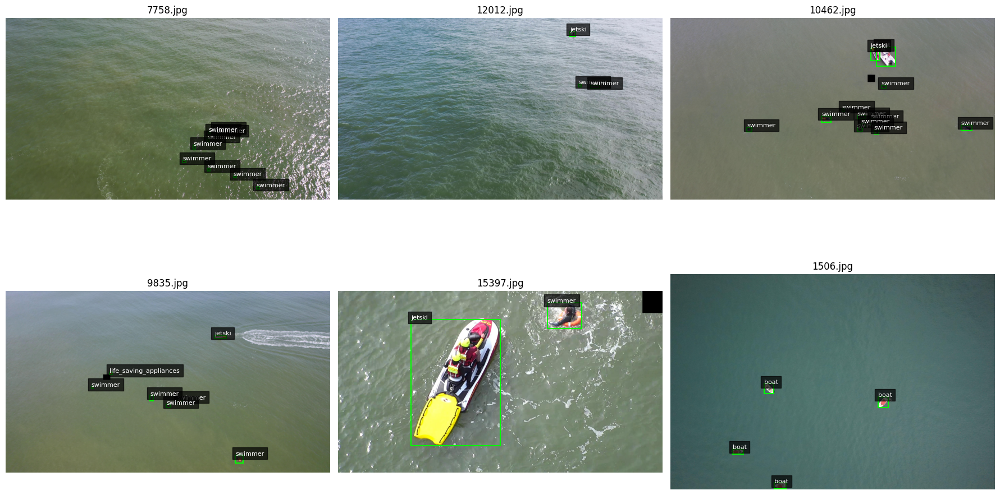

In [2]:



# 1. Dataset paths
PROJECT = Path(r"E:\lifeguardDron")

DATASET_DIR = (
    PROJECT / "data_prepared" / "detection"
    / "SeaDronesSee_ODv2"
)

with open(DATASET_DIR / "dataset.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Resolve validation images directory
val_path = Path(config["val"])

if not val_path.is_absolute():
    val_path = (DATASET_DIR / val_path).resolve()

# 2. Class names
names = config["names"]

if isinstance(names, list):
    class_names = names
else:
    class_names = [
        names[i] for i in range(len(names))
    ]

# 3. Find validation images
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in val_path.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print(f"Validation images: {len(images)}")
print(f"Classes: {class_names}")

# 4. Random sample
random.seed(42)
sample = random.sample(images, min(6, len(images)))

# YOLO dataset convention: images/... -> labels/...
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, image_path in zip(axes, sample):
    image = cv2.imread(str(image_path))

    if image is None:
        ax.set_title(f"Cannot read: {image_path.name}")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    ax.imshow(image)

    # Find corresponding label path
    parts = list(image_path.parts)
    try:
        idx = parts.index("images")
        parts[idx] = "labels"
        label_path = Path(*parts).with_suffix(".txt")
    except ValueError:
        label_path = None

    if label_path and label_path.exists():
        with open(label_path, "r", encoding="utf-8") as f:
            lines = f.readlines()

        for line in lines:
            values = line.split()

            if len(values) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, values)
            cls = int(cls)

            # YOLO normalized coordinates -> pixels
            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            box_w = bw * width
            box_h = bh * height

            rect = Rectangle(
                (x1, y1),
                box_w,
                box_h,
                linewidth=1.5,
                edgecolor="lime",
                facecolor="none",
            )
            ax.add_patch(rect)

            name = (
                class_names[cls]
                if 0 <= cls < len(class_names)
                else f"Unknown class {cls}"
            )

            ax.text(
                x1,
                max(0, y1 - 3),
                name,
                color="white",
                fontsize=8,
                bbox=dict(facecolor="black", alpha=0.7),
            )

    ax.set_title(image_path.name)
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:
from pathlib import Path
from collections import Counter
import yaml

In [6]:
DATASET_YAML = Path(
    r"E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml"
)

with DATASET_YAML.open("r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

names = data["names"]
val_path = Path(data["val"])

# Resolve the validation images directory
if not val_path.is_absolute():
    val_path = (DATASET_YAML.parent / val_path).resolve()

# Ultralytics datasets commonly use images/ and labels/
if val_path.name == "images":
    labels_path = val_path.parent / "labels"
else:
    labels_path = val_path.parent / "labels" / val_path.name

counts = Counter()
bad_lines = []
label_files = list(labels_path.glob("*.txt"))

for file in label_files:
    for line_no, line in enumerate(
        file.read_text(encoding="utf-8").splitlines(), start=1
    ):
        parts = line.split()

        if not parts:
            continue

        try:
            class_id = int(parts[0])
        except ValueError:
            bad_lines.append((file.name, line_no, "Invalid class ID"))
            continue

        if class_id < 0 or class_id >= len(names):
            bad_lines.append((file.name, line_no, f"Out-of-range ID: {class_id}"))
            continue

        counts[class_id] += 1

print("Validation labels directory:", labels_path)
print("Label files found:", len(label_files))
print("\nGround-truth instances per class:")

for class_id in range(len(names)):
    name = names[class_id] if isinstance(names, list) else names[class_id]
    print(f"{class_id}: {str(name):25s} {counts[class_id]:,}")

print("\nInvalid label lines:", len(bad_lines))
for item in bad_lines[:20]:
    print(item)

Validation labels directory: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\images\labels\val
Label files found: 0

Ground-truth instances per class:
0: swimmer                   0
1: boat                      0
2: jetski                    0
3: life_saving_appliances    0
4: buoy                      0

Invalid label lines: 0


In [7]:
for class_id in range(len(names)):
    name = names[class_id]
    print(f"{class_id}: {str(name):25s} {counts[class_id]:,}")

0: swimmer                   0
1: boat                      0
2: jetski                    0
3: life_saving_appliances    0
4: buoy                      0


In [8]:
from pathlib import Path
import yaml

DATASET_YAML = Path(
    r"E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml"
)

with DATASET_YAML.open("r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("=== DATASET CONFIG ===")
print("YAML:", DATASET_YAML)
print("Train:", data.get("train"))
print("Val:", data.get("val"))
print("Names:", data.get("names"))

val_value = Path(str(data["val"]))

if val_value.is_absolute():
    val_path = val_value
else:
    val_path = (DATASET_YAML.parent / val_value).resolve()

print("\n=== VALIDATION PATH ===")
print("Resolved path:", val_path)
print("Exists:", val_path.exists())
print("Is directory:", val_path.is_dir())

if val_path.is_dir():
    images = [
        p for p in val_path.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    print("Images found:", len(images))
    print("Sample images:", [str(p) for p in images[:3]])

print("\n=== SEARCH FOR LABEL FILES ===")
for folder in [DATASET_YAML.parent, val_path.parent, val_path]:
    if folder.exists():
        found = list(folder.rglob("*.txt"))
        print(f"\nFolder: {folder}")
        print("TXT files found:", len(found))
        print("Examples:", [str(p) for p in found[:5]])

=== DATASET CONFIG ===
YAML: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml
Train: images/train
Val: images/val
Names: {0: 'swimmer', 1: 'boat', 2: 'jetski', 3: 'life_saving_appliances', 4: 'buoy'}

=== VALIDATION PATH ===
Resolved path: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\images\val
Exists: True
Is directory: True
Images found: 1547
Sample images: ['E:\\lifeguardDron\\data_prepared\\detection\\SeaDronesSee_ODv2\\images\\val\\1003.jpg', 'E:\\lifeguardDron\\data_prepared\\detection\\SeaDronesSee_ODv2\\images\\val\\1018.jpg', 'E:\\lifeguardDron\\data_prepared\\detection\\SeaDronesSee_ODv2\\images\\val\\1032.jpg']

=== SEARCH FOR LABEL FILES ===

Folder: E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2
TXT files found: 10477
Examples: ['E:\\lifeguardDron\\data_prepared\\detection\\SeaDronesSee_ODv2\\labels\\train\\100.txt', 'E:\\lifeguardDron\\data_prepared\\detection\\SeaDronesSee_ODv2\\labels\\train\\1000.txt', 'E:\\lifeguardDron

### Step: Validation Dataset Integrity Audit

**الهدف:** فحص ملفات الـ Validation Dataset والتأكد من وجود الـ labels وصحة تنسيقها قبل تقييم الموديل.

**What this cell does:**
- Counts the validation images and label files.
- Checks for empty label files.
- Counts ground-truth objects for each class.
- Detects invalid YOLO label lines.

**Results:**
- Validation images: 1,547
- Validation label files: 1,547
- Empty label files: 0
- Invalid label lines: 0
- Total ground-truth instances: 9,630

**Key observation:** The dataset contains different numbers of objects per class. The `swimmer` class has 6,206 instances, while `life_saving_appliances` has only 330.

**Conclusion:** The basic label-file integrity checks passed. However, this does not guarantee that every bounding box has valid coordinates or that every annotation is visually correct. These require additional checks.



In [9]:
from pathlib import Path
from collections import Counter
import yaml

dataset_dir = Path(
    r"E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2"
)

with (dataset_dir / "dataset.yaml").open("r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

names = data["names"]
labels_dir = dataset_dir / "labels" / "val"

counts = Counter()
bad_lines = []
empty_files = 0

label_files = list(labels_dir.glob("*.txt"))

for file in label_files:
    lines = file.read_text(encoding="utf-8").splitlines()

    if not any(line.strip() for line in lines):
        empty_files += 1

    for line_no, line in enumerate(lines, start=1):
        parts = line.split()

        if not parts:
            continue

        try:
            class_id = int(parts[0])
        except ValueError:
            bad_lines.append((file.name, line_no, "Invalid class ID"))
            continue

        if class_id not in names:
            bad_lines.append((file.name, line_no, f"Unknown class ID: {class_id}"))
            continue

        counts[class_id] += 1

print("Validation images:", 1547)
print("Validation label files:", len(label_files))
print("Empty label files:", empty_files)

print("\nGround-truth instances per class:")
for class_id, name in names.items():
    print(f"{class_id}: {name:25s} {counts[class_id]:,}")

print("\nInvalid label lines:", len(bad_lines))
for item in bad_lines[:20]:
    print(item)

Validation images: 1547
Validation label files: 1547
Empty label files: 0

Ground-truth instances per class:
0: swimmer                   6,206
1: boat                      2,214
2: jetski                    320
3: life_saving_appliances    330
4: buoy                      560

Invalid label lines: 0


### Step: Evaluate the Trained YOLO Model

**الهدف:** تقييم أداء الموديل المدرَّب `best.pt` على الـ Validation Dataset، لمعرفة مدى قدرته على اكتشاف الأجسام وتصنيفها بشكل صحيح.

**What this cell does:**
- Loads the trained YOLO model from `best.pt`.
- Evaluates the model on the validation images and labels.
- Calculates **Precision, Recall, mAP@50, and mAP@50–95**.
- Helps identify which classes perform well and which need improvement.

**Why is this important?**

Before retraining the model, we need to measure its current performance and identify the weak classes. This helps us make decisions based on evaluation results rather than guessing.

**Expected output:** Evaluation metrics showing the model's overall performance and its performance across individual classes.

In [1]:
from ultralytics import YOLO

model = YOLO(
    r"E:\lifeguardDron\runs\detect\seadrones_smoke_test\weights\best.pt"
)

metrics = model.val(
    data=r"E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml",
    imgsz=640,
    batch=4,
    device=0
)

print("Classes:", model.names)
print("Precision:", metrics.box.p)
print("Recall:", metrics.box.r)
print("mAP50:", metrics.box.ap50)
print("mAP50-95:", metrics.box.ap)
print("Class indices:", metrics.box.ap_class_index)

Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1071.6±574.3 MB/s, size: 617.7 KB)
val: Scanning E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val.cache... 1547 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1547/1547  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 387/387 5.6it/s 1:09s<0.1ss
                   all       1547       9630       0.85      0.527      0.558      0.284
               swimmer       1286       6206      0.722      0.588      0.577      0.204
                  boat        915       2214      0.893      0.848       0.89      0.533
                jetski        320        320      0.693      0.775      0.761      0.384
life_saving_appliances        191        330          1          0     0.0998  

### Step: Visual Inspection of Ground-Truth Annotations

**الهدف:** التأكد بصريًا من صحة الـ Bounding Boxes والـ Class Labels في الـ Validation Dataset قبل تقييم الموديل.

**What this cell does:**
- Selects random images from the validation set.
- Loads the corresponding YOLO label files.
- Converts normalized bounding-box coordinates into pixel coordinates.
- Draws bounding boxes and class names on the images.

**Why is this important?**

Incorrect annotations can negatively affect model evaluation and training. Visual inspection helps detect misplaced boxes, incorrect class labels, or missing annotations.

**Result:** The inspected bounding boxes appear correctly positioned around the objects.

**Conclusion:** Proceed to model evaluation, while remembering that inspecting a few images does not guarantee that the entire dataset is error-free.

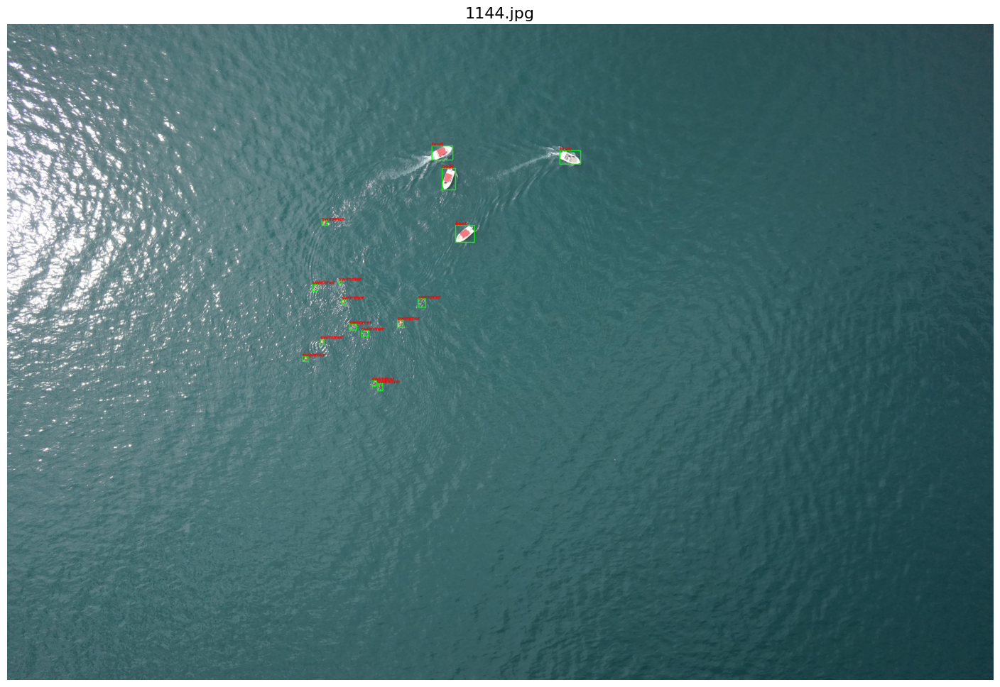

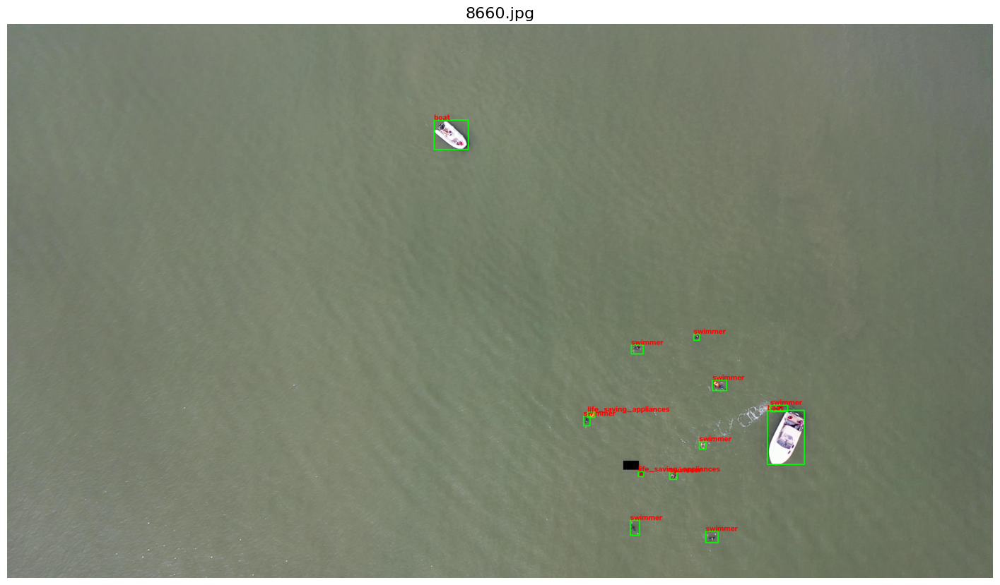

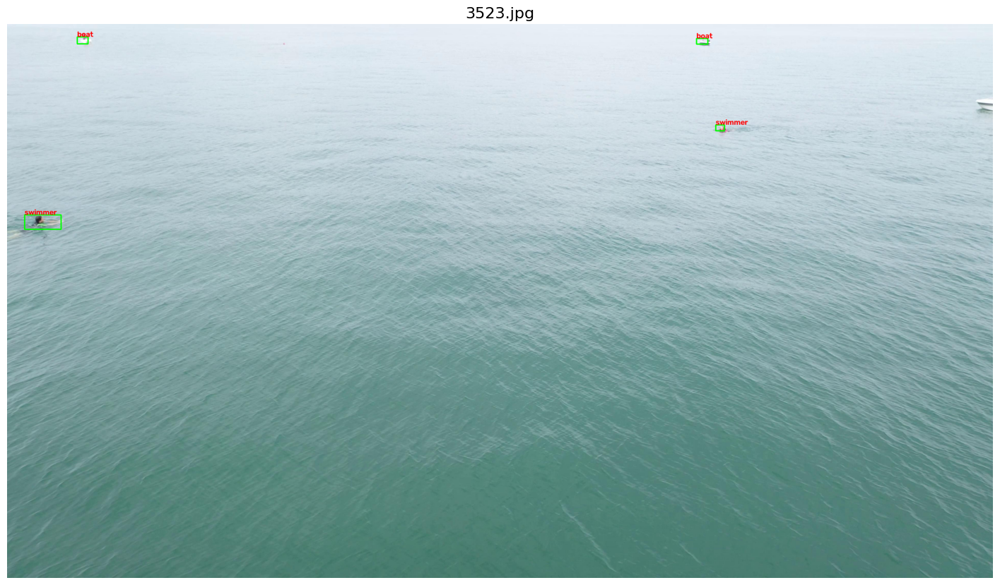

In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

root = Path(r"E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2")
names = ["swimmer", "boat", "jetski", "life_saving_appliances", "buoy"]
images = list((root / "images/val").glob("*.jpg"))

for path in random.sample(images, 3):
    img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    label = root / "labels/val" / f"{path.stem}.txt"

    for line in label.read_text().splitlines():
        c, x, y, bw, bh = map(float, line.split())
        p1 = (int((x-bw/2)*w), int((y-bh/2)*h))
        p2 = (int((x+bw/2)*w), int((y+bh/2)*h))
        cv2.rectangle(img, p1, p2, (0, 255, 0), 4)
        cv2.putText(img, names[int(c)], (p1[0], max(30, p1[1])),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 3)

    plt.figure(figsize=(18, 12))
    plt.imshow(img)
    plt.title(path.name, fontsize=16)
    plt.axis("off")
    plt.show()

Step: YOLO11n Model Evaluation on the Validation Dataset
Objective: Evaluate the trained YOLO11n model using the validation dataset and measure its object-detection performance.
What this cell does:
- Loads the trained model from best.pt.
- Runs inference on 1,547 validation images.
- Matches predictions against ground-truth bounding boxes.
- Calculates Precision, Recall, mAP@50, and mAP@50–95 for each class.
Model configuration:
- Model: YOLO11n
- Parameters: 2,598,023
- Input image size: 640 × 640
- Device: NVIDIA GTX 1650 (4 GB VRAM)
- Validation instances: 9,630
Evaluation results:
Class	Precision	Recall	mAP@50	mAP@50–95
swimmer	0.722	0.588	0.577	0.204
boat	0.893	0.848	0.890	0.533
jetski	0.693	0.775	0.761	0.384
life_saving_appliances	1.000	0.000	0.100	0.033
buoy	0.945	0.426	0.462	0.268
Overall	0.850	0.527	0.558	0.284


Key findings:
- boat has the strongest overall detection performance.
- jetski achieves good recall and mAP@50.
- swimmer detection needs improvement, particularly localization quality.
- buoy has high precision but relatively low recall, meaning many actual buoys are missed.
- life_saving_appliances has zero recall at the evaluated operating threshold, despite a reported precision of 1.0. Its mAP@50 is also very low.
Conclusion: The model's performance varies significantly across classes. The life_saving_appliances result requires further investigation before retraining. The next step is to inspect the model's class-specific predictions, confidence scores, and evaluation metrics to determine why it fails to detect this class.


In [3]:

from pathlib import Path
from ultralytics import YOLO
import torch
import pandas as pd

# 1. Define paths
PROJECT_ROOT = Path(r"E:\lifeguardDron")
DATASET_YAML = (
    PROJECT_ROOT
    / "data_prepared"
    / "detection"
    / "SeaDronesSee_ODv2"
    / "dataset.yaml"
)
WEIGHTS = (
    PROJECT_ROOT
    / "runs"
    / "detect"
    / "seadrones_smoke_test"
    / "weights"
    / "best.pt"
)

# 2. Check that the required files exist
assert DATASET_YAML.is_file(), f"Dataset YAML not found: {DATASET_YAML}"
assert WEIGHTS.is_file(), f"Model weights not found: {WEIGHTS}"

# 3. Select device
device = 0 if torch.cuda.is_available() else "cpu"

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Evaluation device: {device}")

if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# 4. Load trained YOLO11n model
model = YOLO(str(WEIGHTS))

print("\nModel classes:")
print(model.names)

# 5. Evaluate on the validation dataset
metrics = model.val(
    data=str(DATASET_YAML),
    split="val",
    imgsz=640,
    batch=4,             # Conservative for GTX 1650 4 GB VRAM
    device=device,
    workers=2,
    plots=True,
    verbose=True
)

# 6. Extract official Ultralytics metrics
box_metrics = metrics.box
class_names = model.names

results = []

for class_id, class_name in class_names.items():
    results.append({
        "Class": class_name,
        "Precision": float(box_metrics.p[class_id]),
        "Recall": float(box_metrics.r[class_id]),
        "mAP@50": float(box_metrics.ap50[class_id]),
        "mAP@50–95": float(box_metrics.ap[class_id]),
    })

# Add the overall mean metrics
results.append({
    "Class": "Overall (macro average)",
    "Precision": float(box_metrics.mp),
    "Recall": float(box_metrics.mr),
    "mAP@50": float(box_metrics.map50),
    "mAP@50–95": float(box_metrics.map),
})

results_df = pd.DataFrame(results)

print("\nYOLO11n Validation Results")
display(
    results_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "mAP@50": "{:.3f}",
        "mAP@50–95": "{:.3f}",
    })
)

# 7. Save results for later analysis
output_dir = PROJECT_ROOT / "reports" / "model_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "yolo11n_validation_metrics.csv"
results_df.to_csv(csv_path, index=False)

print(f"\nResults saved to: {csv_path}")
print(f"Ultralytics validation output: {metrics.save_dir}")


PyTorch version: 2.11.0+cu128
CUDA available: True
Evaluation device: 0
GPU: NVIDIA GeForce GTX 1650

Model classes:
{0: 'swimmer', 1: 'boat', 2: 'jetski', 3: 'life_saving_appliances', 4: 'buoy'}
Ultralytics 8.4.182  Python-3.11.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 8.7±13.7 ms, read: 777.0±1035.3 MB/s, size: 549.2 KB)
val: Scanning E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val.cache... 1547 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1547/1547 1.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 387/387 7.8it/s 49.7s0.2sss
                   all       1547       9630       0.85      0.527      0.558      0.284
               swimmer       1286       6206      0.722      0.588      0.577      0.204
                  boat        915       2214      0.

,Class,Precision,Recall,mAP@50,mAP@50–95
0,swimmer,0.722,0.588,0.577,0.204
1,boat,0.893,0.848,0.890,0.533
2,jetski,0.693,0.775,0.761,0.384
3,life_saving_appliances,1.000,0.000,0.100,0.033
4,buoy,0.945,0.426,0.462,0.268
5,Overall (macro average),0.850,0.527,0.558,0.284



Results saved to: E:\lifeguardDron\reports\model_evaluation\yolo11n_validation_metrics.csv
Ultralytics validation output: E:\lifeguardDron\notebooks\runs\detect\val-9


## Raw-vs-post diagnostic — Step 1: paths and model config

Confirm the checkpoint, dataset, and validation paths exist, and that the model's
class names match the dataset (`3 = life_saving_appliances`). Read-only; no inference.

In [4]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROJECT = Path(r"E:\lifeguardDron")
CHECKPOINT = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "weights" / "best.pt"
DATASET_DIR = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2"
VAL_IMAGES = DATASET_DIR / "images" / "val"
VAL_LABELS = DATASET_DIR / "labels" / "val"

for p in (CHECKPOINT, DATASET_DIR, VAL_IMAGES, VAL_LABELS):
    print(("OK       " if p.exists() else "MISSING  ") + str(p))

model = YOLO(str(CHECKPOINT))
print("Model classes:", dict(model.names))
print("Number of classes:", len(model.names))
print("Expected class 3:", model.names[3])

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

OK       E:\lifeguardDron\runs\detect\seadrones_smoke_test\weights\best.pt
OK       E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2
OK       E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\images\val
OK       E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\labels\val
Model classes: {0: 'swimmer', 1: 'boat', 2: 'jetski', 3: 'life_saving_appliances', 4: 'buoy'}
Number of classes: 5
Expected class 3: life_saving_appliances
CUDA available: True
Device: NVIDIA GeForce GTX 1650


## Raw-vs-post diagnostic — Step 2: select 20 validation images

Deterministically select the first 20 validation images (sorted by filename) that
contain at least one `life_saving_appliances` ground-truth box. Verify every selected
label has a matching image, and count the class-3 ground-truth boxes in the sample.
No inference yet.

In [5]:
from pathlib import Path

TARGET = 3   # life_saving_appliances

# image stem -> image file path
img_map = {p.stem: p for p in VAL_IMAGES.glob("*") if p.is_file()}

def has_class3(label_path):
    for line in label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if parts and int(float(parts[0])) == TARGET:
            return True
    return False

# deterministic: sorted label filenames
with_gt3 = sorted(lbl.stem for lbl in VAL_LABELS.glob("*.txt") if has_class3(lbl))
SAMPLE = with_gt3[:20]

print("Images with class-3 GT (total):", len(with_gt3))
print("Sample size:", len(SAMPLE))
print("Sample stems:", SAMPLE)

# check missing image-label pairs within the sample
missing_images = [s for s in SAMPLE if s not in img_map]
print("Sample stems missing an image file:", missing_images)

# count class-3 GT boxes in the sample
gt3_total = 0
for stem in SAMPLE:
    for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if parts and int(float(parts[0])) == TARGET:
            gt3_total += 1
print("Class-3 ground-truth boxes in the sample:", gt3_total)

Images with class-3 GT (total): 191
Sample size: 20
Sample stems: ['1224', '1230', '1309', '2749', '2754', '2782', '2885', '2890', '2894', '3001', '3004', '3011', '3012', '3016', '3022', '3023', '3102', '3111', '526', '595']
Sample stems missing an image file: []
Class-3 ground-truth boxes in the sample: 28


## Raw-vs-post diagnostic — Step 3: two inference passes

Run the model twice over the same 20 images:
- `post`: deployment post-processing (conf=0.25, class-aware NMS iou=0.6).
- `raw`: NMS effectively disabled (iou=0.999) and near-zero confidence floor (conf=0.0001).

Store per-image boxes as (class, confidence, xyxy) and record each image's
original (height, width) for later ground-truth conversion. No matching yet.

In [6]:
def run_inference(stems, conf_th, iou_th):
    boxes_by_stem = {}
    shapes = {}
    src = [str(img_map[s]) for s in stems]
    for r in model.predict(
        source=src,
        conf=conf_th,
        iou=iou_th,
        imgsz=640,
        device=0,
        save=False,
        save_txt=False,
        plots=False,
        verbose=False,
        stream=True,
    ):
        stem = Path(r.path).stem
        shapes[stem] = (int(r.orig_shape[0]), int(r.orig_shape[1]))
        out = []
        if r.boxes is not None and len(r.boxes) > 0:
            xyxy = r.boxes.xyxy.cpu().numpy()
            conf = r.boxes.conf.cpu().numpy()
            cls = r.boxes.cls.cpu().numpy().astype(int)
            for i in range(len(conf)):
                out.append((int(cls[i]), float(conf[i]), tuple(xyxy[i])))
        boxes_by_stem[stem] = out
    return boxes_by_stem, shapes

post, shapes = run_inference(SAMPLE, conf_th=0.25, iou_th=0.6)
raw, _      = run_inference(SAMPLE, conf_th=0.0001, iou_th=0.999)

print("raw total boxes :", sum(len(v) for v in raw.values()))
print("post total boxes:", sum(len(v) for v in post.values()))
print("raw >= post for every image:",
      all(len(raw[s]) >= len(post[s]) for s in SAMPLE))
print("shapes recorded:", len(shapes))

raw total boxes : 5105
post total boxes: 129
raw >= post for every image: True
shapes recorded: 20


## Raw-vs-post diagnostic — Step 4: match and classify failure modes

For each class-3 ground-truth box, find its best-overlapping raw box (IoU >= 0.5),
separately for class 3 and for all other classes, then classify into one of:
1. weak class-3 score, 2. incorrect class, 3. same-class NMS suppression,
4. localization/scale miss. `detected` = a class-3 box survives post-processing.

Limitation: Ultralytics exposes each box's argmax class and score only, so the
runner-up class score per location is not visible; "iou=0.999" approximates
NMS-off rather than raw logits.

Localization / scale miss
16 / 28



Predicted as swimmer
11 / 28



Predicted as buoy
1 / 28

In [7]:
from collections import Counter

IOU_MATCH = 0.5
CONF_DEPLOY = 0.25

def to_xyxy(cx, cy, w, h, img_w, img_h):
    return (cx - w/2)*img_w, (cy - h/2)*img_h, (cx + w/2)*img_w, (cy + h/2)*img_h

def iou(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    iw = max(0.0, x2 - x1); ih = max(0.0, y2 - y1)
    inter = iw * ih
    aa = (a[2]-a[0]) * (a[3]-a[1]); bb = (b[2]-b[0]) * (b[3]-b[1])
    return inter / (aa + bb - inter + 1e-9)

def best_overlap(boxes, gt, keep_cls=None, skip_cls=None):
    bi, bv = -1, 0.0
    for i, (cls, cf, bb) in enumerate(boxes):
        if keep_cls is not None and cls != keep_cls:
            continue
        if skip_cls is not None and cls == skip_cls:
            continue
        v = iou(bb, gt)
        if v > bv:
            bv, bi = v, i
    return bi, bv

categories = Counter()
detail = []

for stem in SAMPLE:
    h, w = shapes[stem]
    raw_b = raw.get(stem, [])
    post_b = post.get(stem, [])

    gt_boxes = []
    for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if p and int(float(p[0])) == TARGET:
            cx, cy, bw, bh = map(float, p[1:5])
            gt_boxes.append(to_xyxy(cx, cy, bw, bh, w, h))

    for gt in gt_boxes:
        ci, cv = best_overlap(raw_b, gt, keep_cls=TARGET)   # best class-3 raw box
        oi, ov = best_overlap(raw_b, gt, skip_cls=TARGET)   # best other-class raw box

        if cv >= IOU_MATCH:                    # class 3 localized here
            c3_conf = raw_b[ci][1]
            survived = any(iou(pb, gt) >= IOU_MATCH
                           for (pc, pcf, pb) in post_b if pc == TARGET)
            if survived:
                categories["detected (survives post)"] += 1
                detail.append((stem, "detected", round(c3_conf, 3), round(cv, 3)))
            elif c3_conf < CONF_DEPLOY:
                categories["1. weak class-3 score"] += 1
                detail.append((stem, "weak-class3", round(c3_conf, 3), round(cv, 3)))
            else:
                categories["3. same-class NMS suppression"] += 1
                detail.append((stem, "nms-suppressed", round(c3_conf, 3), round(cv, 3)))
        elif ov >= IOU_MATCH:                  # another class localized, class 3 did not
            oc, ocf, _ = raw_b[oi]
            categories["2. incorrect class (pred %s)" % model.names[oc]] += 1
            detail.append((stem, "pred-" + model.names[oc], round(ocf, 3), round(ov, 3)))
        else:                                  # nothing overlaps at IoU >= 0.5
            categories["4. localization/scale miss"] += 1
            detail.append((stem, "miss", None, round(max(cv, ov), 3)))

print("Failure-mode breakdown (class-3 GT boxes in sample):")
for k in sorted(categories):
    print("  %-40s %d" % (k, categories[k]))
print("Total class-3 GT boxes classified:", sum(categories.values()))
print("\nFirst 12 detail rows (image, outcome, best_conf, best_iou):")
for row in detail[:12]:
    print("  ", row)

Failure-mode breakdown (class-3 GT boxes in sample):
  2. incorrect class (pred buoy)           1
  2. incorrect class (pred swimmer)        11
  4. localization/scale miss               16
Total class-3 GT boxes classified: 28

First 12 detail rows (image, outcome, best_conf, best_iou):
   ('1224', 'miss', None, np.float32(0.174))
   ('1230', 'miss', None, np.float32(0.101))
   ('1309', 'miss', None, np.float32(0.099))
   ('2749', 'miss', None, np.float32(0.293))
   ('2749', 'miss', None, np.float32(0.275))
   ('2754', 'miss', None, np.float32(0.281))
   ('2782', 'miss', None, np.float32(0.232))
   ('2885', 'miss', None, np.float32(0.063))
   ('2890', 'miss', None, np.float32(0.274))
   ('2894', 'miss', None, np.float32(0.092))
   ('3001', 'pred-buoy', 0.126, np.float32(0.529))
   ('3001', 'pred-swimmer', 0.336, np.float32(0.503))


## Raw-vs-post diagnostic — Step 5: visualize informative cases

Show the images where a class-3 object was mislabeled as another class, plus a few
pure localization-miss images. GT class 3 = thick green; raw boxes = solid (colored by
class, labeled with confidence); post-NMS = dashed. Goal: confirm whether the
overlapping swimmer/buoy box is on the same object, and see the size/appearance of
the missed objects.

Images to visualize: ['3001', '3004', '3016', '3022', '3023', '3111', '526', '595']


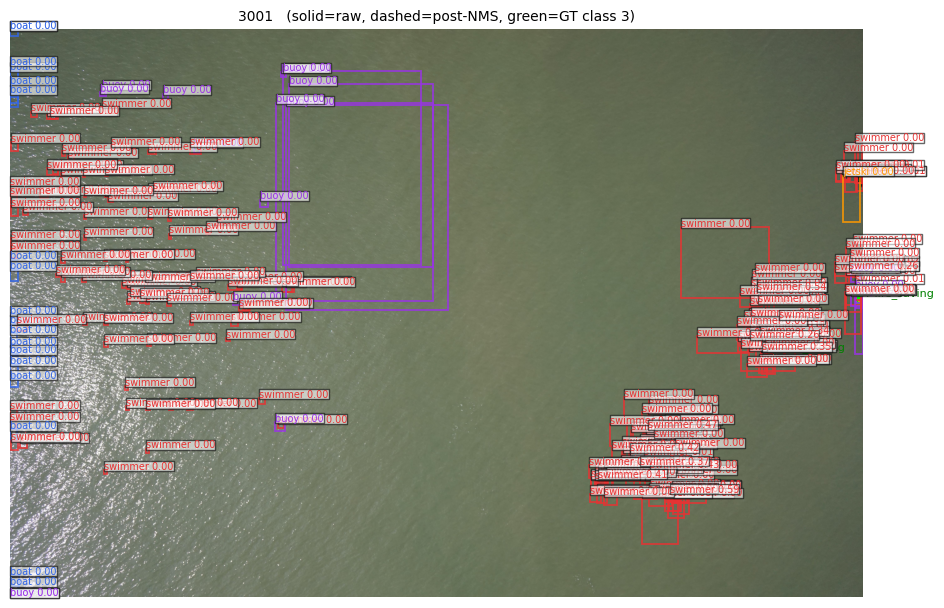

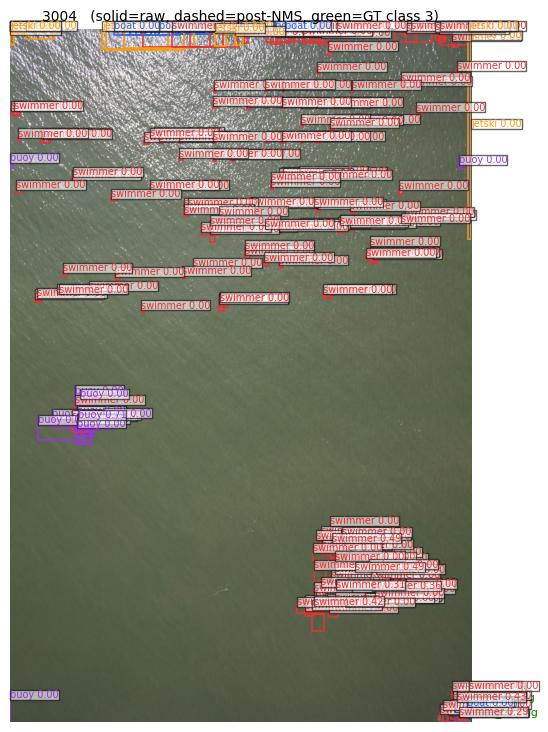

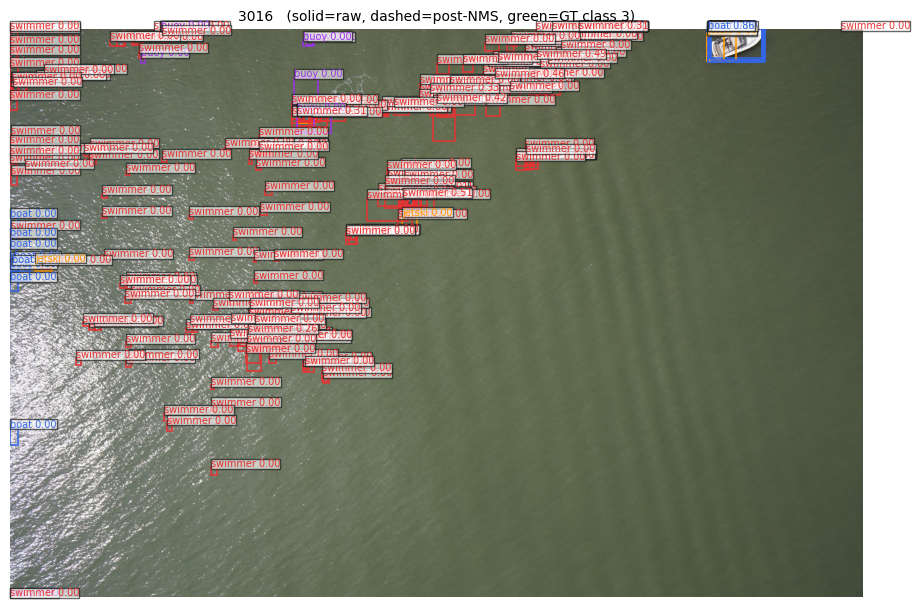

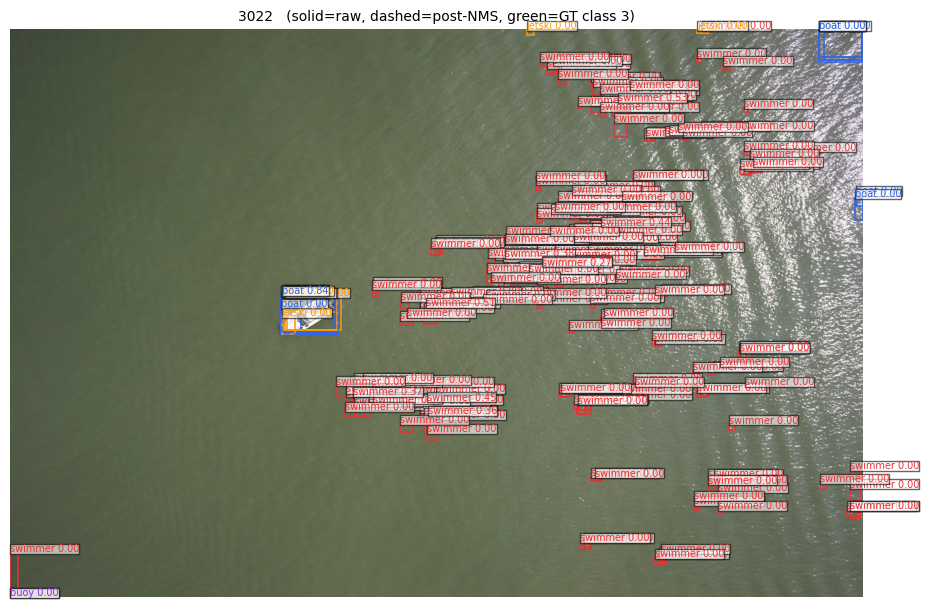

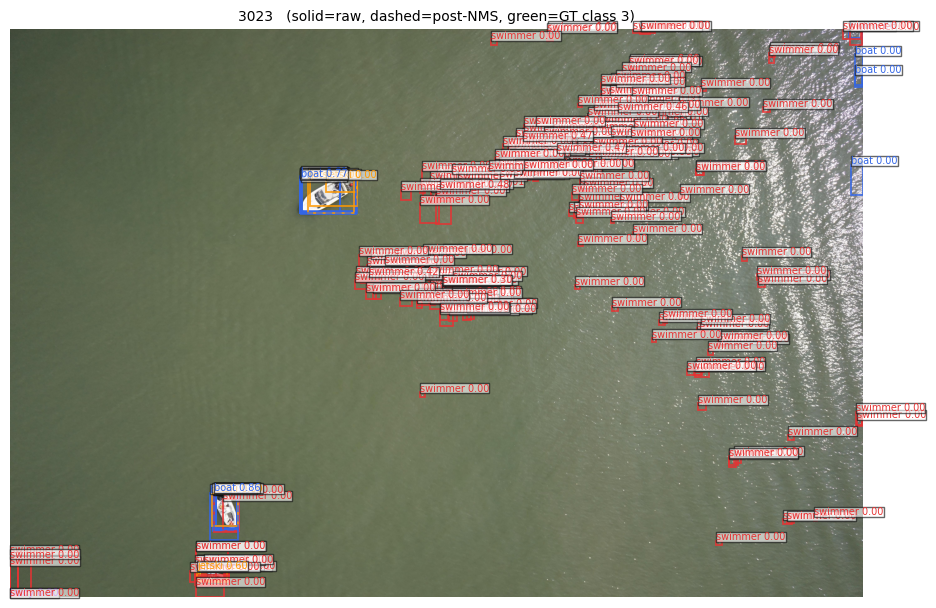

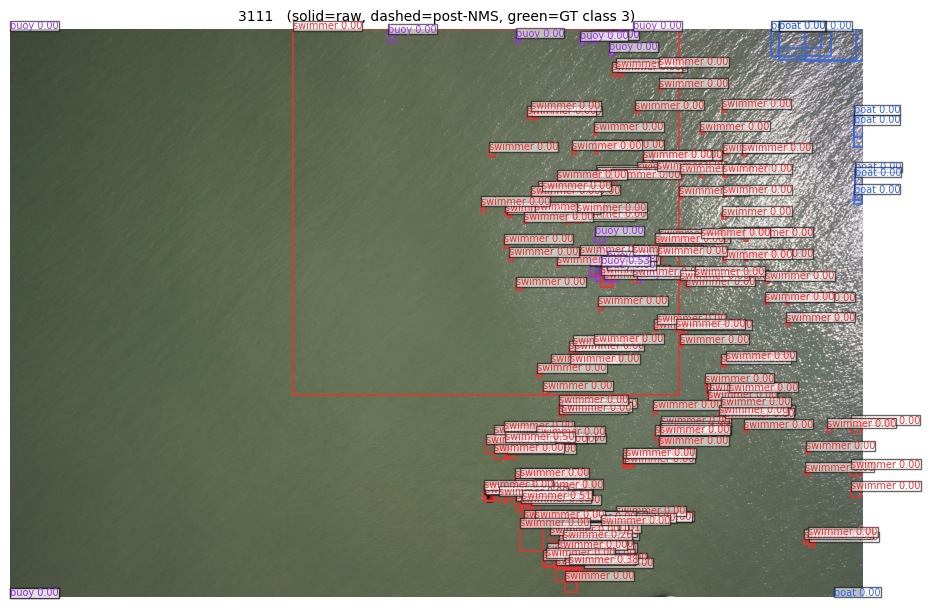

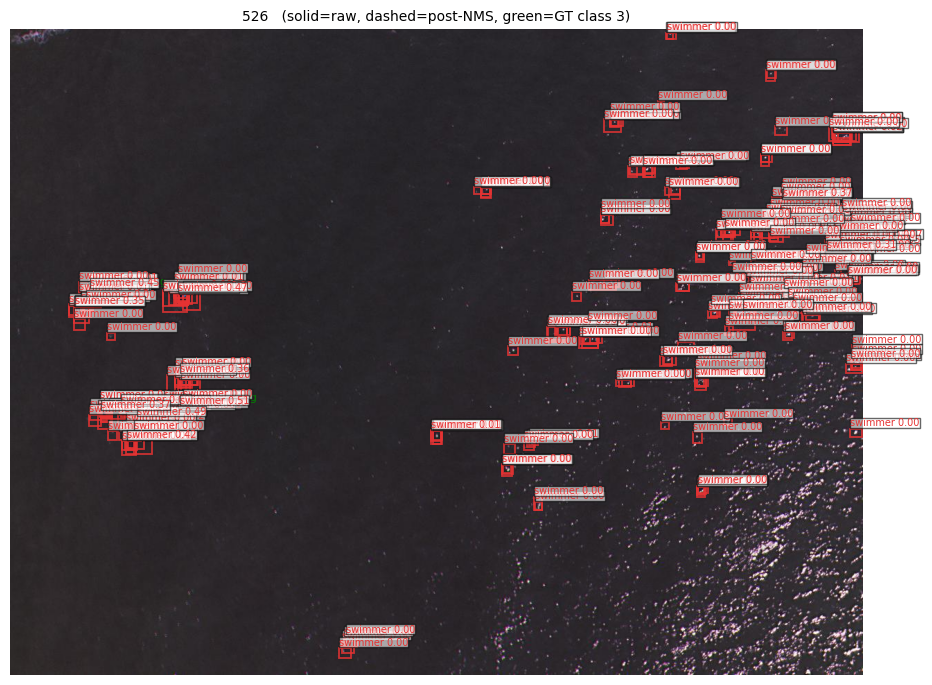

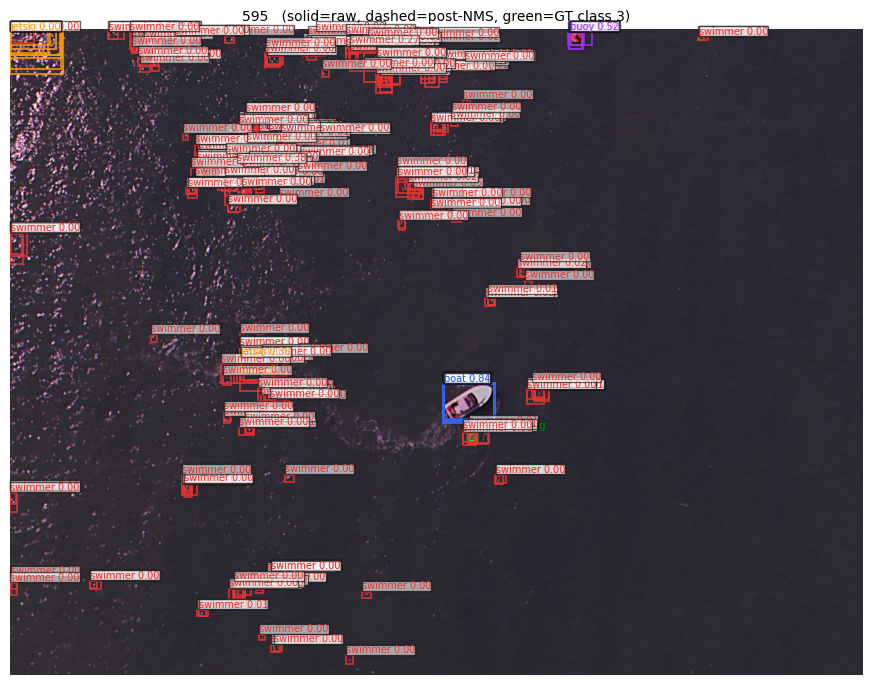

In [8]:
import cv2
import matplotlib.pyplot as plt
from collections import defaultdict

COLORS = {0: (0.9, 0.2, 0.2), 1: (0.2, 0.4, 0.9), 2: (1.0, 0.6, 0.0),
          3: (0.2, 0.8, 0.2), 4: (0.6, 0.2, 0.9)}

# group outcomes per image
outcomes_by_img = defaultdict(list)
for (stem, outcome, cf, iov) in detail:
    outcomes_by_img[stem].append(outcome)

confusion_imgs = sorted(s for s, outs in outcomes_by_img.items()
                        if any(o.startswith("pred-") for o in outs))
miss_imgs = sorted(s for s, outs in outcomes_by_img.items()
                   if all(o == "miss" for o in outs))

viz_stems = (confusion_imgs + miss_imgs[:(8 - len(confusion_imgs))])[:8]
print("Images to visualize:", viz_stems)

def draw_boxes(ax, boxes, linestyle, alpha):
    for (cls, cf, (x1, y1, x2, y2)) in boxes:
        col = COLORS.get(cls, (0, 0, 0))
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                     edgecolor=col, linewidth=1.3, linestyle=linestyle, alpha=alpha))
        ax.text(x1, max(0, y1 - 4), "%s %.2f" % (model.names[cls], cf),
                color=col, fontsize=7, bbox=dict(facecolor="white", alpha=0.6, pad=0))

for stem in viz_stems:
    h, w = shapes[stem]
    img = cv2.cvtColor(cv2.imread(str(img_map[stem])), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.imshow(img)

    # GT class-3 boxes (thick green)
    for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if p and int(float(p[0])) == TARGET:
            cx, cy, bw, bh = map(float, p[1:5])
            x1, y1, x2, y2 = to_xyxy(cx, cy, bw, bh, w, h)
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                         edgecolor=(0, 1, 0), linewidth=2.5))
            ax.text(x1, y1 - 6, "GT life_saving", color=(0, 0.5, 0), fontsize=8)

    draw_boxes(ax, raw.get(stem, []), "-", 0.85)   # raw: solid
    draw_boxes(ax, post.get(stem, []), "--", 0.7)  # post-NMS: dashed

    ax.set_title(stem + "   (solid=raw, dashed=post-NMS, green=GT class 3)", fontsize=10)
    ax.axis("off")
    plt.show()

## Raw-vs-post diagnostic — Step 5b: quantify raw vs post overlap

For every class-3 GT box, print the best raw class-3 box, the best raw other-class
box, and the best *post-NMS* other-class box (the box that would actually be a
reported detection). This separates real misclassification from raw-only noise.

In [9]:
print("image | raw class3 (iou/conf) | raw other (cls/iou/conf) | post other (cls/iou/conf)")

for stem in SAMPLE:
    h, w = shapes[stem]
    raw_b = raw.get(stem, [])
    post_b = post.get(stem, [])

    for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if not (p and int(float(p[0])) == TARGET):
            continue
        cx, cy, bw, bh = map(float, p[1:5])
        gt = to_xyxy(cx, cy, bw, bh, w, h)

        ci, cv = best_overlap(raw_b, gt, keep_cls=TARGET)   # best raw class-3
        oi, ov = best_overlap(raw_b, gt, skip_cls=TARGET)   # best raw other-class
        pi, pv = best_overlap(post_b, gt, skip_cls=TARGET)  # best post other-class

        r_c3  = "%.2f/%.3f" % (cv, raw_b[ci][1]) if ci >= 0 else "-"
        r_oth = "%s/%.2f/%.3f" % (model.names[raw_b[oi][0]], ov, raw_b[oi][1]) if oi >= 0 else "-"
        p_oth = "%s/%.2f/%.3f" % (model.names[post_b[pi][0]], pv, post_b[pi][1]) if pi >= 0 else "-"

        print("%s | %s | %s | %s" % (stem, r_c3, r_oth, p_oth))

image | raw class3 (iou/conf) | raw other (cls/iou/conf) | post other (cls/iou/conf)
1224 | - | boat/0.17/0.001 | boat/0.02/0.840
1230 | - | jetski/0.10/0.002 | boat/0.02/0.805
1309 | - | jetski/0.10/0.003 | boat/0.04/0.765
2749 | - | swimmer/0.29/0.242 | -
2749 | - | swimmer/0.27/0.241 | -
2754 | - | swimmer/0.28/0.001 | -
2782 | - | swimmer/0.23/0.001 | -
2885 | - | swimmer/0.06/0.126 | -
2890 | - | swimmer/0.27/0.326 | swimmer/0.27/0.326
2894 | - | swimmer/0.09/0.000 | -
3001 | - | buoy/0.53/0.126 | -
3001 | - | swimmer/0.50/0.336 | swimmer/0.50/0.336
3001 | - | swimmer/0.66/0.262 | swimmer/0.66/0.262
3001 | - | swimmer/0.17/0.260 | swimmer/0.16/0.345
3004 | - | swimmer/0.74/0.430 | swimmer/0.74/0.430
3004 | - | swimmer/0.63/0.293 | swimmer/0.63/0.293
3011 | - | swimmer/0.39/0.490 | swimmer/0.39/0.490
3012 | - | swimmer/0.43/0.555 | swimmer/0.43/0.555
3016 | - | swimmer/0.55/0.490 | swimmer/0.55/0.490
3022 | - | swimmer/0.88/0.140 | swimmer/0.83/0.380
3023 | - | swimmer/0.69/0.465 |

## Raw-vs-post diagnostic — Step 6: summary report

Compute the refined tallies, print them, and write a new summary markdown file.
Refuses to overwrite an existing file.

In [10]:
from pathlib import Path
from datetime import datetime

real_misclass = 0
raw_only = 0
pure_miss = 0
rows = []

for stem in SAMPLE:
    h, w = shapes[stem]
    raw_b = raw.get(stem, [])
    post_b = post.get(stem, [])
    for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if not (p and int(float(p[0])) == TARGET):
            continue
        cx, cy, bw, bh = map(float, p[1:5])
        gt = to_xyxy(cx, cy, bw, bh, w, h)
        ci, cv = best_overlap(raw_b, gt, keep_cls=TARGET)
        oi, ov = best_overlap(raw_b, gt, skip_cls=TARGET)
        pi, pv = best_overlap(post_b, gt, skip_cls=TARGET)

        if cv >= IOU_MATCH:
            rows.append((stem, "class3 localized", round(raw_b[ci][1], 3), round(cv, 3)))
        elif pv >= IOU_MATCH:
            real_misclass += 1
            rows.append((stem, "real misclass " + model.names[post_b[pi][0]],
                         round(post_b[pi][1], 3), round(pv, 3)))
        elif ov >= IOU_MATCH:
            raw_only += 1
            rows.append((stem, "raw-only " + model.names[raw_b[oi][0]],
                         round(raw_b[oi][1], 3), round(ov, 3)))
        else:
            pure_miss += 1
            rows.append((stem, "miss", None, round(max(cv, ov), 3)))

total = real_misclass + raw_only + pure_miss
print("Real misclassifications:", real_misclass)
print("Raw-only overlaps:      ", raw_only)
print("Pure localization misses:", pure_miss)
print("Total:", total)

out_dir = PROJECT / "reports" / "ponytail_diagnostic_life_saving_appliances" / "raw_vs_post_analysis"
out_path = out_dir / "raw_vs_post_summary.md"
if out_path.exists():
    raise SystemExit("REFUSING to overwrite: " + str(out_path))
out_dir.mkdir(parents=True, exist_ok=True)

L = [
    "# Raw-vs-post analysis — life_saving_appliances",
    "",
    "Generated: " + datetime.now().isoformat(timespec="seconds"),
    "",
    "## Sample",
    "- 20 images, 28 class-3 GT boxes (deterministic, first 20 sorted stems with class-3 GT)",
    "- raw pass: conf=0.0001, iou=0.999 (NMS effectively off)",
    "- post pass: conf=0.25, iou=0.6 (deployment)",
    "- match IoU: 0.5",
    "",
    "## Refined failure-mode tally",
    "- real misclassification as swimmer: %d" % real_misclass,
    "- raw-only overlap (sub-threshold confidence): %d" % raw_only,
    "- pure localization miss: %d" % pure_miss,
    "- weak class-3 score: 0",
    "- same-class NMS suppression: 0",
    "",
    "Class 3 was never the argmax class at any of the 28 objects (raw pass).",
    "",
    "## Per-box detail",
    "| image | outcome | conf | iou |",
    "|-------|---------|------|-----|",
]
for (stem, outcome, cf, iov) in rows:
    L.append("| %s | %s | %s | %s |" % (stem, outcome, cf, iov))

out_path.write_text("\n".join(L) + "\n", encoding="utf-8")
print("Wrote:", out_path)

Real misclassifications: 10
Raw-only overlaps:       2
Pure localization misses: 16
Total: 28
Wrote: E:\lifeguardDron\reports\ponytail_diagnostic_life_saving_appliances\raw_vs_post_analysis\raw_vs_post_summary.md


## Object-size analysis — Step 7: per-class box size

Measure the normalized bounding-box size (width, height, area as a fraction of the
image) for each class on the train and validation sets. Tests whether
`life_saving_appliances` objects are systematically smaller than the other classes,
which would explain the localization misses. Label-only; no model or inference.

In [11]:
from collections import defaultdict
import numpy as np

def class_sizes(labels_dir):
    sizes = defaultdict(list)
    for lbl in labels_dir.glob("*.txt"):
        for line in lbl.read_text(encoding="utf-8").splitlines():
            p = line.split()
            if len(p) < 5:
                continue
            cls = int(float(p[0]))
            cx, cy, w, h = map(float, p[1:5])
            sizes[cls].append((w, h, w * h))
    return sizes

for split, labels_dir in [("val", VAL_LABELS),
                          ("train", DATASET_DIR / "labels" / "train")]:
    print("=== %s ===" % split)
    sizes = class_sizes(labels_dir)
    print("%-26s %9s %9s %9s %10s %9s" %
          ("class", "count", "med_w", "med_h", "med_area", "pct<0.01"))
    for cls in sorted(sizes):
        a = np.array(sizes[cls])
        med_w = np.median(a[:, 0]); med_h = np.median(a[:, 1]); med_a = np.median(a[:, 2])
        small = (a[:, 2] < 0.01).mean() * 100
        print("%-26s %9d %9.4f %9.4f %10.4f %8.1f%%" %
              (model.names[cls], len(a), med_w, med_h, med_a, small))
    print()

=== val ===
class                          count     med_w     med_h   med_area  pct<0.01
swimmer                         6206    0.0130    0.0185     0.0002     98.4%
boat                            2214    0.0352    0.0384     0.0015     96.9%
jetski                           320    0.0281    0.0440     0.0009     90.6%
life_saving_appliances           330    0.0082    0.0111     0.0001    100.0%
buoy                             560    0.0047    0.0123     0.0001    100.0%

=== train ===
class                          count     med_w     med_h   med_area  pct<0.01
swimmer                        37096    0.0112    0.0171     0.0002     99.7%
boat                           13022    0.0310    0.0370     0.0011     93.1%
jetski                          2330    0.0219    0.0276     0.0007     98.8%
life_saving_appliances           923    0.0083    0.0116     0.0001    100.0%
buoy                            4389    0.0130    0.0301     0.0004    100.0%



## Step 8 — per-class recall on the 20-image sample

Compute one-to-one IoU-matched recall for every class on the same 20 images using the
post-NMS (conf=0.25) boxes. Compares class 3 against equally-tiny buoy to separate the
"small object" explanation from "under-representation / swimmer confusion".

Recall — نسبة الأجسام الحقيقية المكتشفة صح
boat
20/20

buoy
6/8

jetski
5/7

swimmer
35/129

life_saving_appliances
0/28

In [12]:
def recall_for_class(cls_id, boxes_by_stem, conf_th, iou_th):
    TP = 0
    total_gt = 0
    for stem in SAMPLE:
        h, w = shapes[stem]
        gt_boxes = []
        for line in (VAL_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
            p = line.split()
            if p and int(float(p[0])) == cls_id:
                cx, cy, bw, bh = map(float, p[1:5])
                gt_boxes.append(to_xyxy(cx, cy, bw, bh, w, h))
        total_gt += len(gt_boxes)

        cands = sorted([(cf, bb) for (cls, cf, bb) in boxes_by_stem.get(stem, [])
                        if cls == cls_id and cf >= conf_th],
                       key=lambda x: -x[0])
        unmatched = set(range(len(gt_boxes)))
        for (cf, pb) in cands:
            best_j, best_v = -1, 0.0
            for j in unmatched:
                v = iou(pb, gt_boxes[j])
                if v > best_v:
                    best_v, best_j = v, j
            if best_j >= 0 and best_v >= iou_th:
                unmatched.discard(best_j)
                TP += 1

    recall = TP / total_gt if total_gt else 0.0
    return TP, total_gt, recall

print("Per-class recall on the 20-image sample (conf=0.25, IoU=0.5):")
for cls in range(5):
    TP, tot, rec = recall_for_class(cls, post, 0.25, 0.5)
    print("  %-26s TP=%4d  GT=%4d  recall=%.3f" % (model.names[cls], TP, tot, rec))
    

Per-class recall on the 20-image sample (conf=0.25, IoU=0.5):
  swimmer                    TP=  35  GT= 129  recall=0.271
  boat                       TP=  20  GT=  20  recall=1.000
  jetski                     TP=   5  GT=   7  recall=0.714
  life_saving_appliances     TP=   0  GT=  28  recall=0.000
  buoy                       TP=   6  GT=   8  recall=0.750


Train-label audit

Train images with class-3 GT: 665


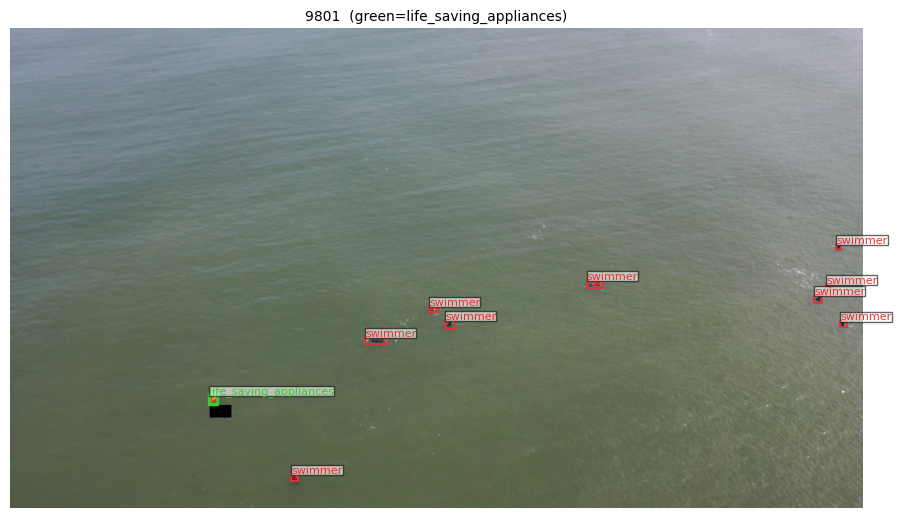

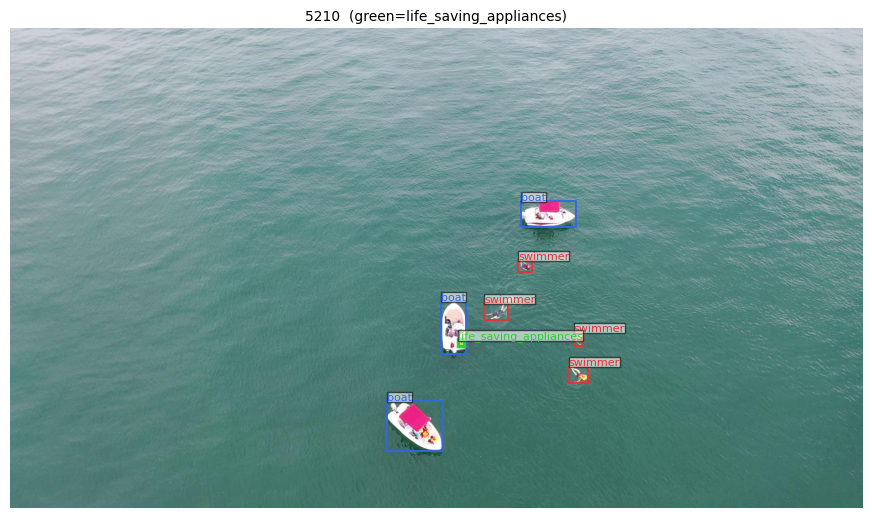

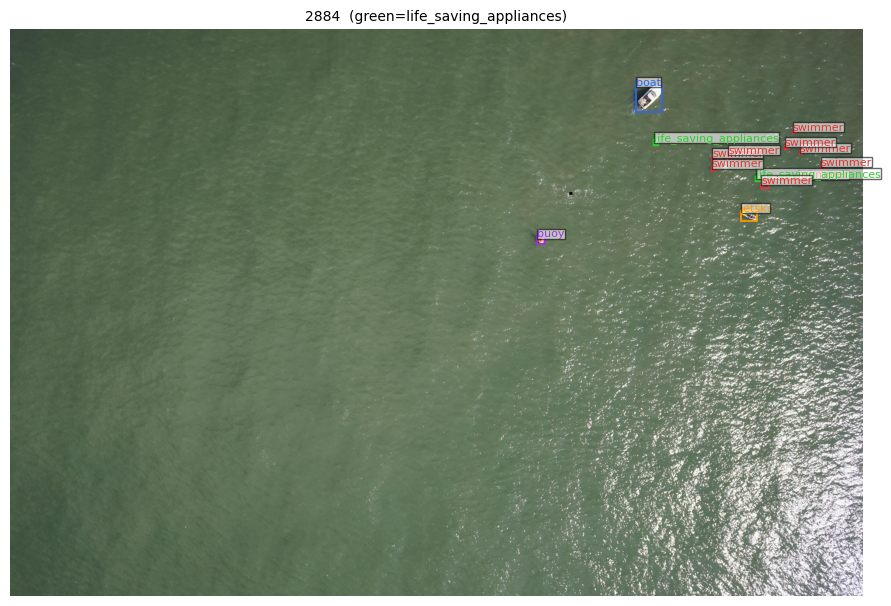

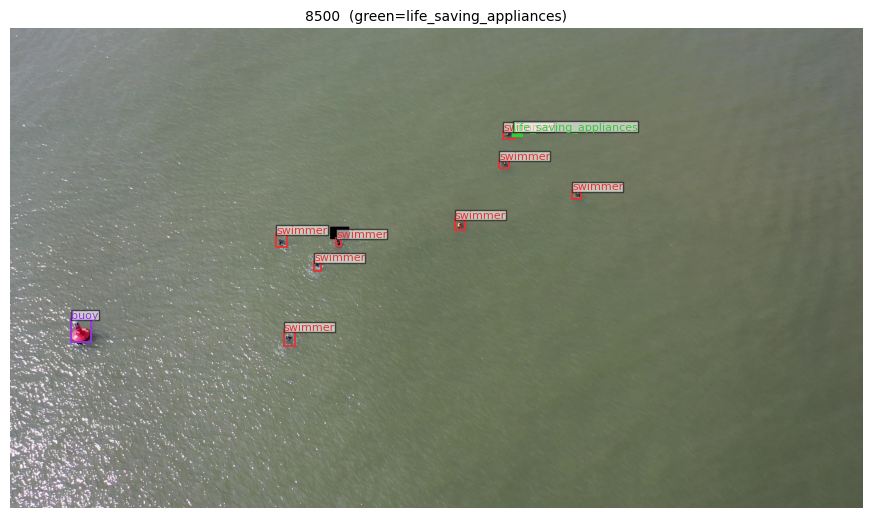

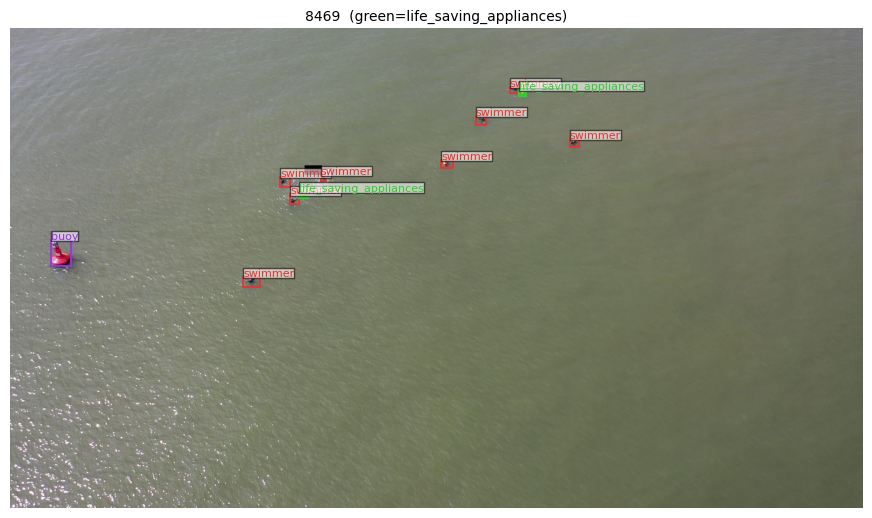

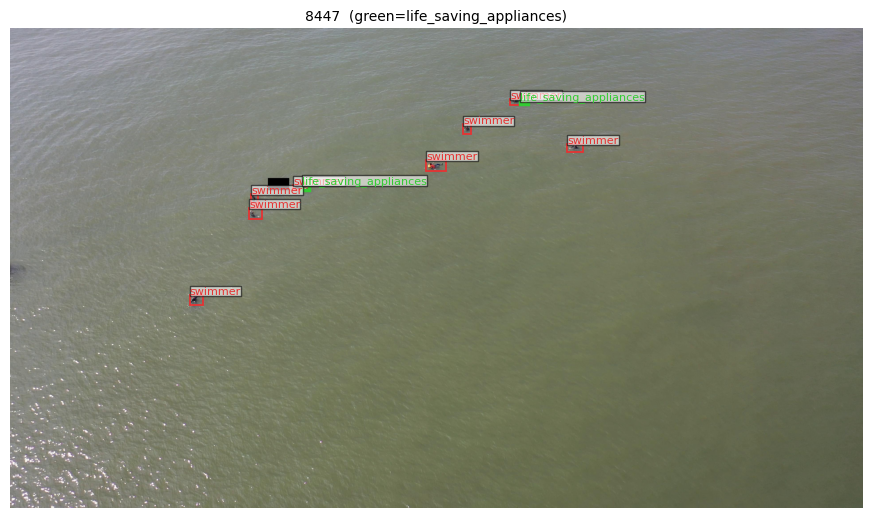

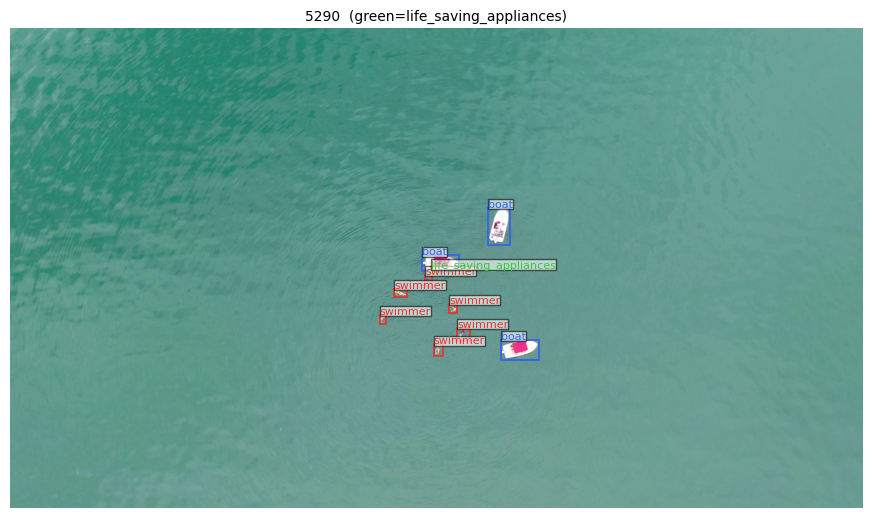

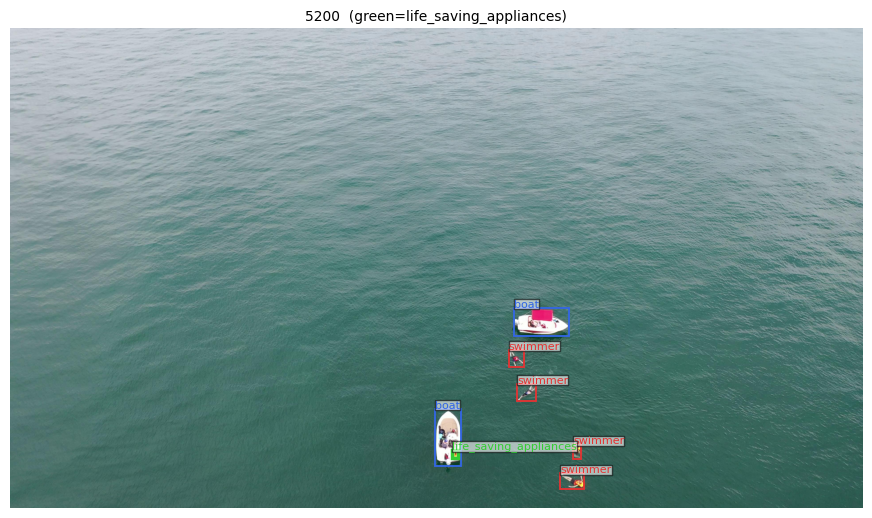

In [13]:
import random
import cv2
import matplotlib.pyplot as plt

TRAIN_IMAGES = DATASET_DIR / "images" / "train"
TRAIN_LABELS = DATASET_DIR / "labels" / "train"

train_img_map = {p.stem: p for p in TRAIN_IMAGES.glob("*") if p.is_file()}

# find train images that contain class-3 GT
train_with_gt3 = sorted(
    lbl.stem for lbl in TRAIN_LABELS.glob("*.txt")
    if any(int(float(l.split()[0])) == TARGET for l in lbl.read_text().splitlines() if l.strip())
)
print("Train images with class-3 GT:", len(train_with_gt3))

# deterministic random sample
random.seed(42)
sample = random.sample(train_with_gt3, 8)

COLORS = {0:(0.9,0.2,0.2),1:(0.2,0.4,0.9),2:(1.0,0.6,0.0),3:(0.2,0.8,0.2),4:(0.6,0.2,0.9)}

for stem in sample:
    img = cv2.cvtColor(cv2.imread(str(train_img_map[stem])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.imshow(img)
    for line in (TRAIN_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        cx, cy, bw, bh = map(float, p[1:5])
        x1, y1, x2, y2 = to_xyxy(cx, cy, bw, bh, w, h)
        col = COLORS.get(cls, (0,0,0))
        lw = 2.5 if cls == TARGET else 1.3
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1, fill=False, edgecolor=col, linewidth=lw))
        ax.text(x1, max(0,y1-4), model.names[cls], color=col, fontsize=8,
                bbox=dict(facecolor="white", alpha=0.6, pad=0))
    ax.set_title(stem + "  (green=life_saving_appliances)", fontsize=10)
    ax.axis("off")
    plt.show()

## Train-label audit — Step 9: inspect class-3 annotations

Visualize a random sample of training images that contain `life_saving_appliances`
ground-truth boxes, with all boxes drawn (class 3 highlighted). Confirms whether the
923 class-3 annotations are correct life-saving appliances, or mislabeled. Label-only;
no model.

Train images with class-3 GT: 665
Total class-3 train boxes: 923


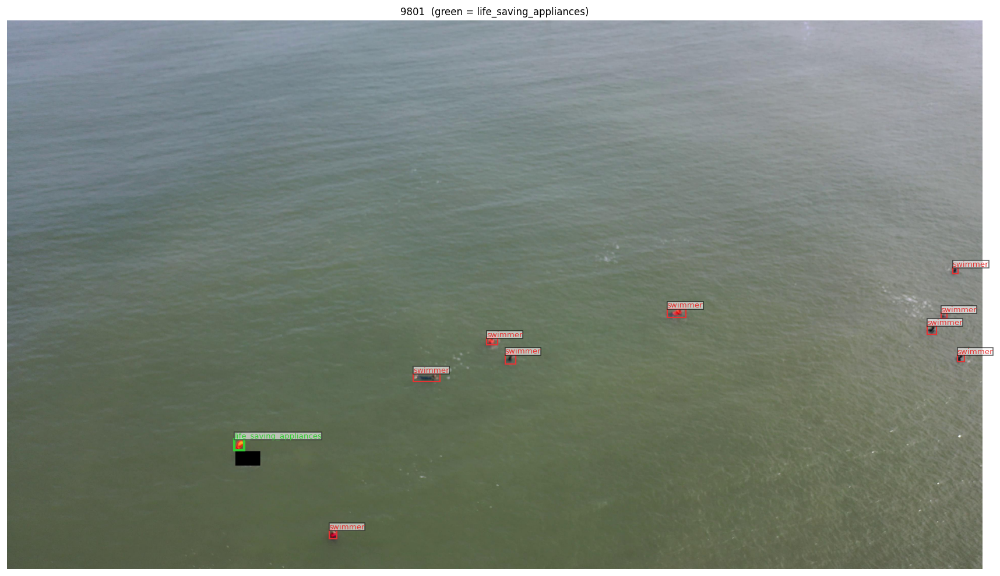

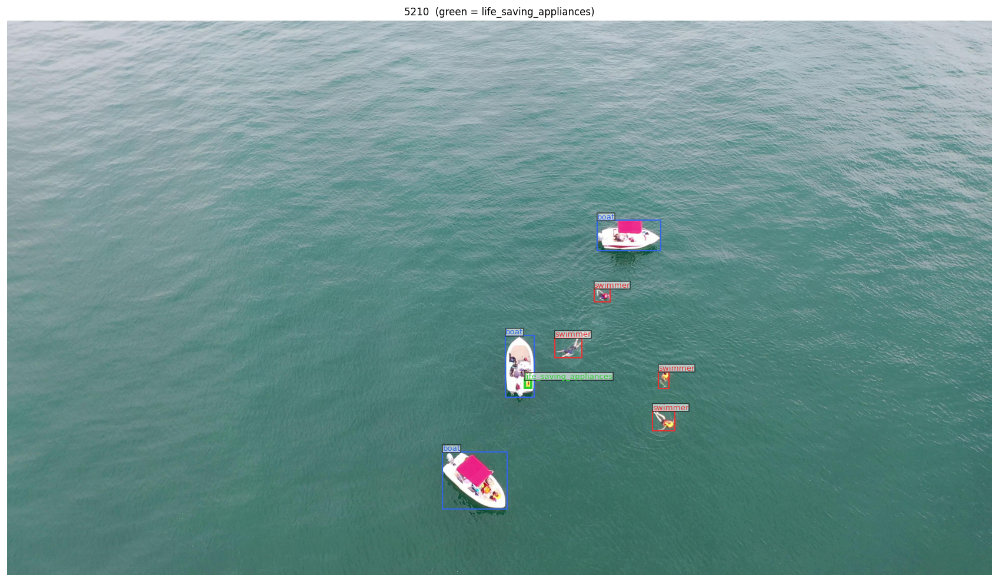

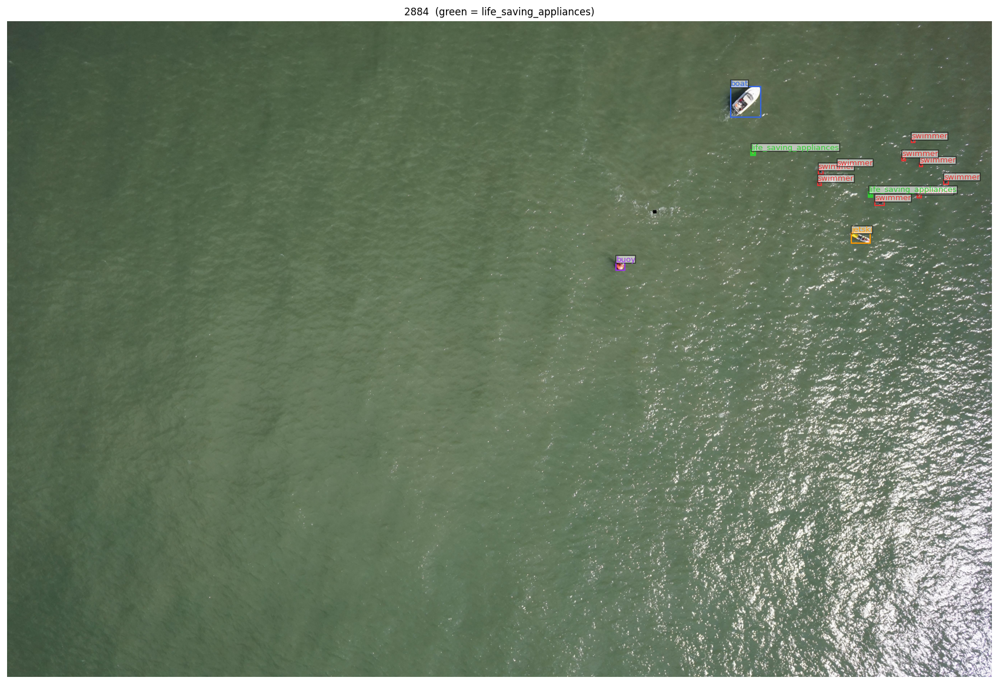

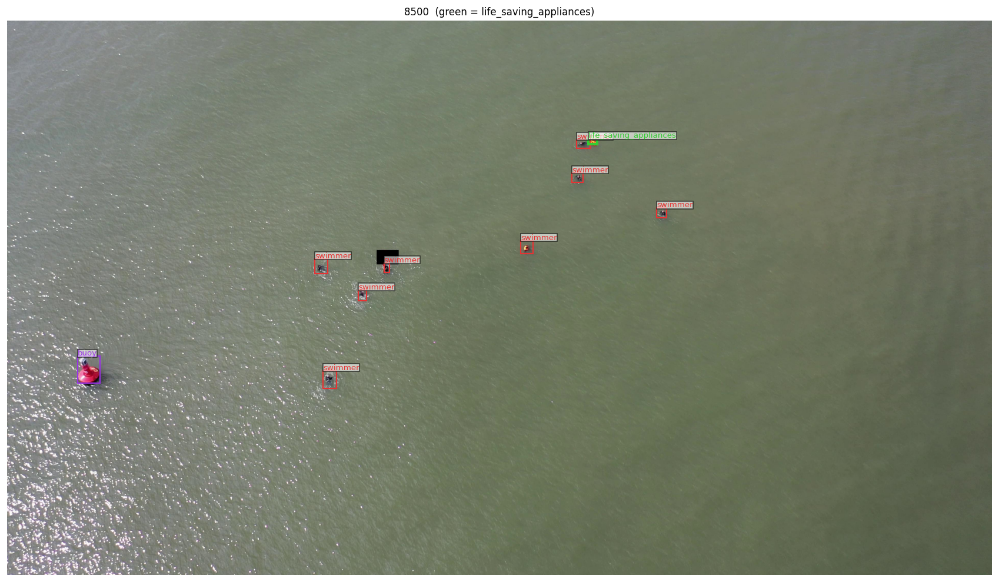

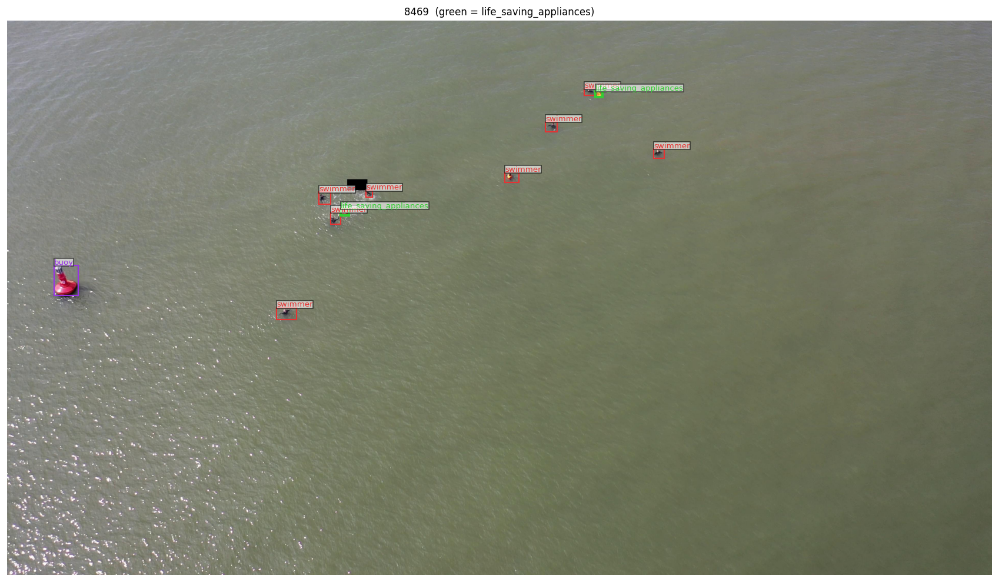

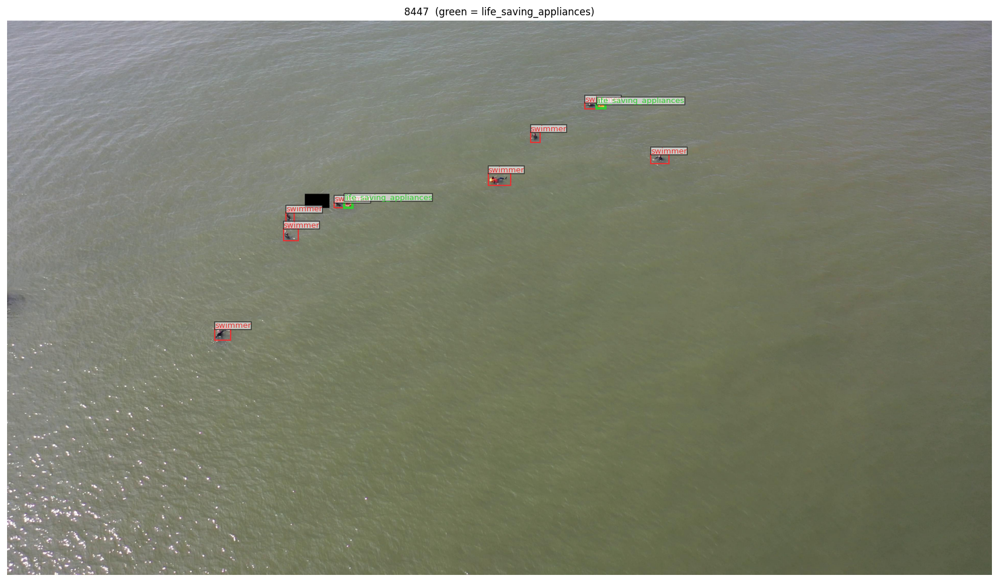

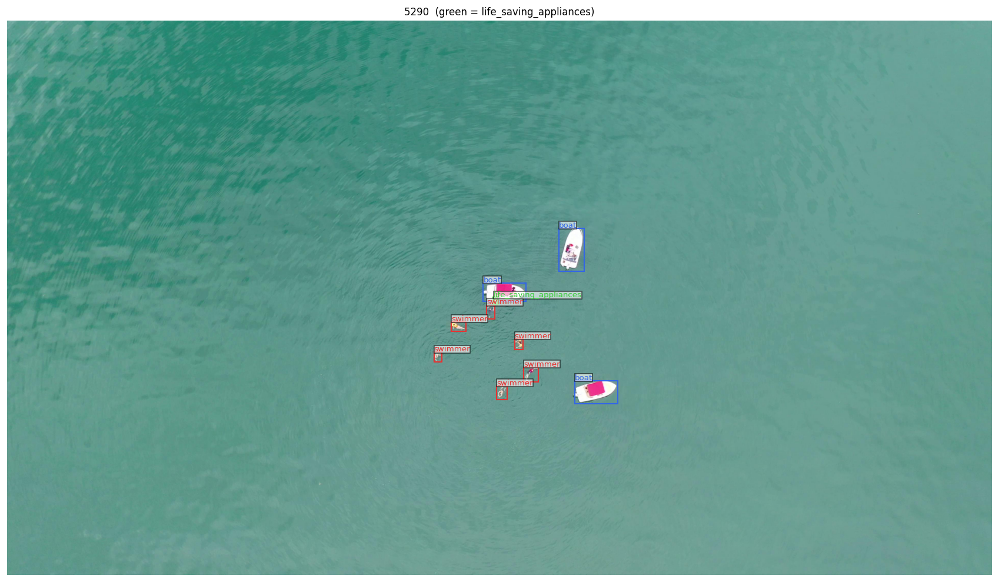

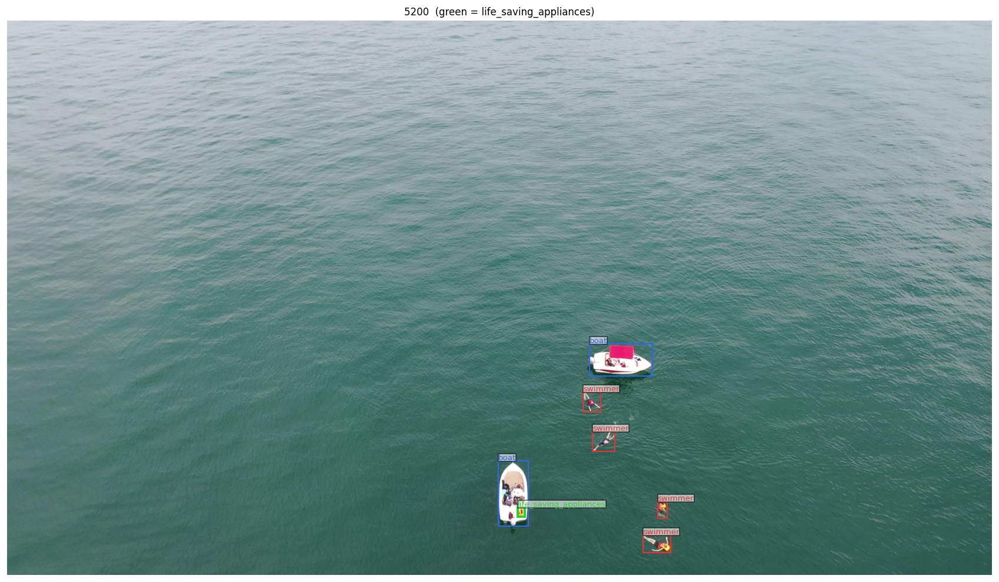

In [15]:
import random
import cv2
import matplotlib.pyplot as plt

TRAIN_IMAGES = DATASET_DIR / "images" / "train"
TRAIN_LABELS = DATASET_DIR / "labels" / "train"

train_img_map = {p.stem: p for p in TRAIN_IMAGES.glob("*") if p.is_file()}

train_with_gt3 = sorted(
    lbl.stem for lbl in TRAIN_LABELS.glob("*.txt")
    if any(int(float(l.split()[0])) == TARGET
           for l in lbl.read_text(encoding="utf-8").splitlines() if l.strip())
)
print("Train images with class-3 GT:", len(train_with_gt3))

c3_total = sum(
    1 for lbl in TRAIN_LABELS.glob("*.txt")
    for line in lbl.read_text(encoding="utf-8").splitlines()
    if line.strip() and int(float(line.split()[0])) == TARGET
)
print("Total class-3 train boxes:", c3_total)

random.seed(42)
sample = random.sample(train_with_gt3, 8)

COLORS = {0: (0.9, 0.2, 0.2), 1: (0.2, 0.4, 0.9), 2: (1.0, 0.6, 0.0),
          3: (0.2, 0.8, 0.2), 4: (0.6, 0.2, 0.9)}

for stem in sample:
    img = cv2.cvtColor(cv2.imread(str(train_img_map[stem])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(18, 14), dpi=120)
    ax.imshow(img)
    for line in (TRAIN_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        cx, cy, bw, bh = map(float, p[1:5])
        x1, y1, x2, y2 = to_xyxy(cx, cy, bw, bh, w, h)
        col = COLORS.get(cls, (0, 0, 0))
        lw = 2.5 if cls == TARGET else 1.3
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                     edgecolor=col, linewidth=lw))
        ax.text(x1, max(0, y1 - 4), model.names[cls], color=col, fontsize=8,
                bbox=dict(facecolor="white", alpha=0.6, pad=0))
    ax.set_title(stem + "  (green = life_saving_appliances)", fontsize=10)
    ax.axis("off")
    plt.show()

## Train-label audit — Step 10: per-box zoom inspection

For a deterministic sample of 8 train images, show each class-3 box as a full image
plus an enlarged crop with the target box and nearby annotated objects. Reuses the
earlier helpers. Upscaling uses interpolation and does not restore missing detail.

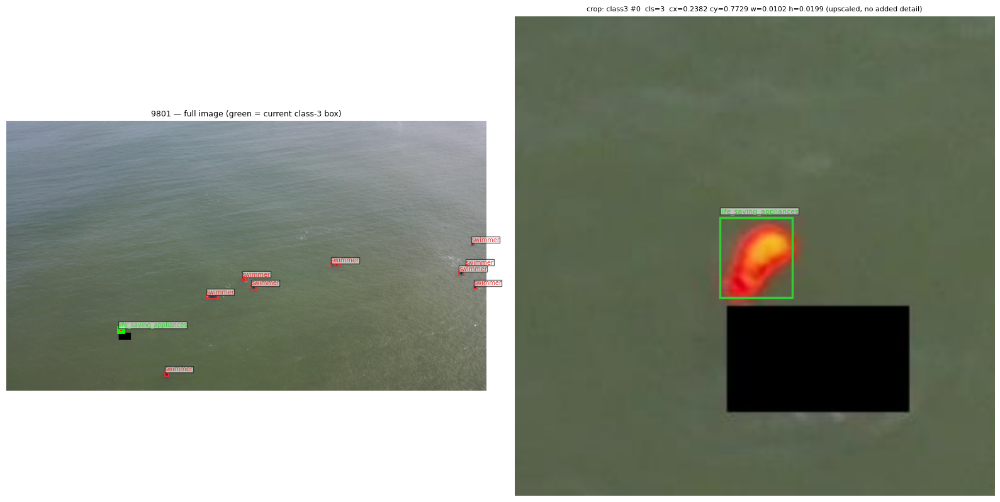

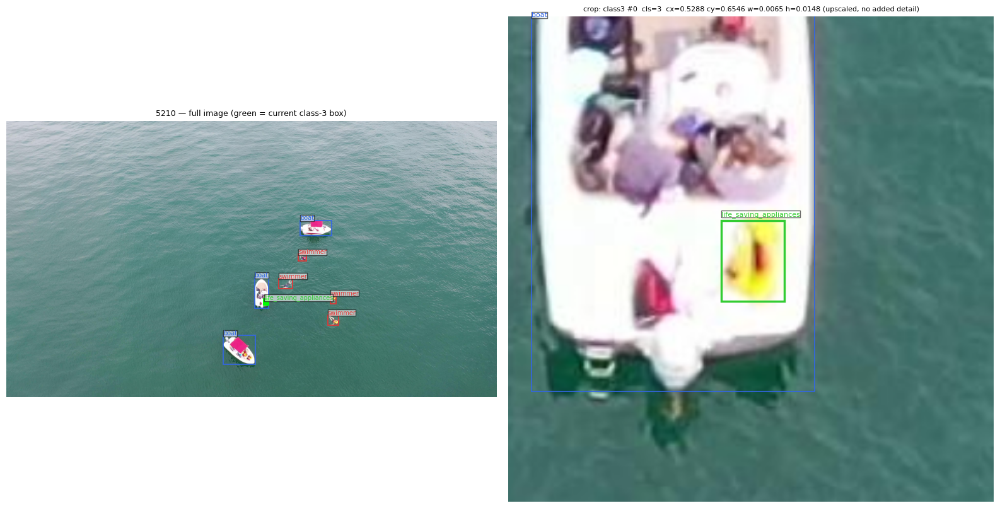

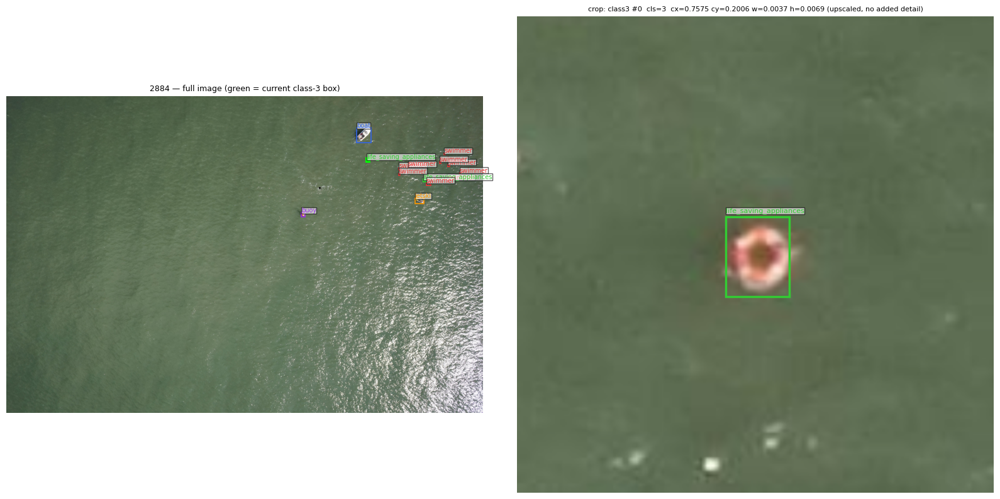

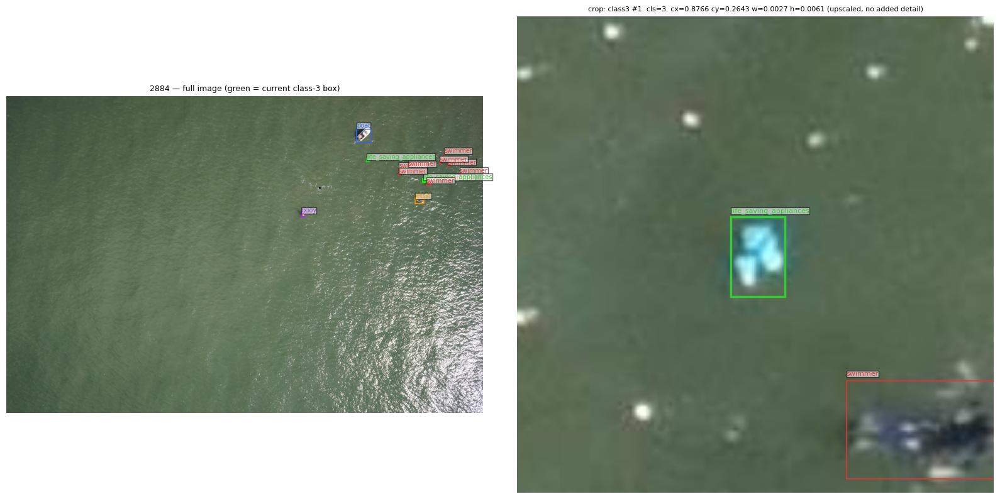

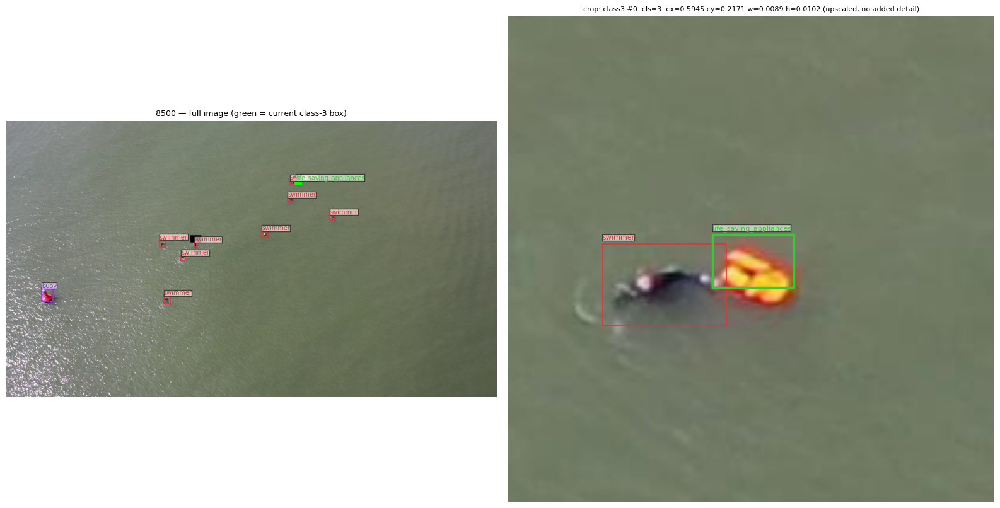

...

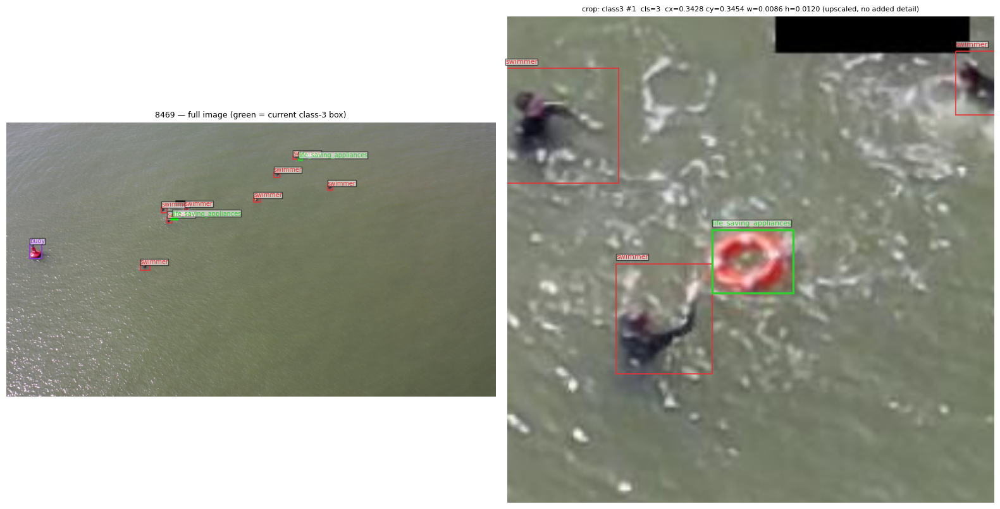

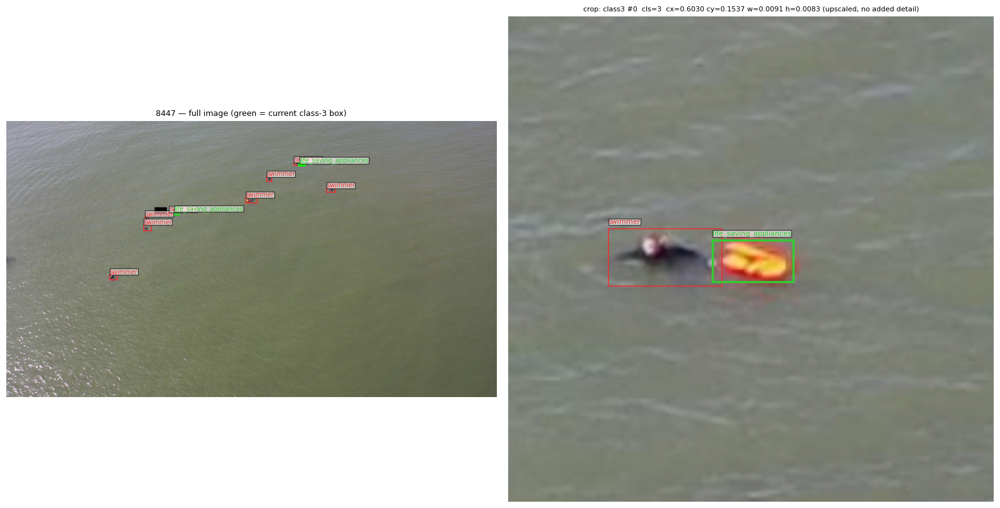

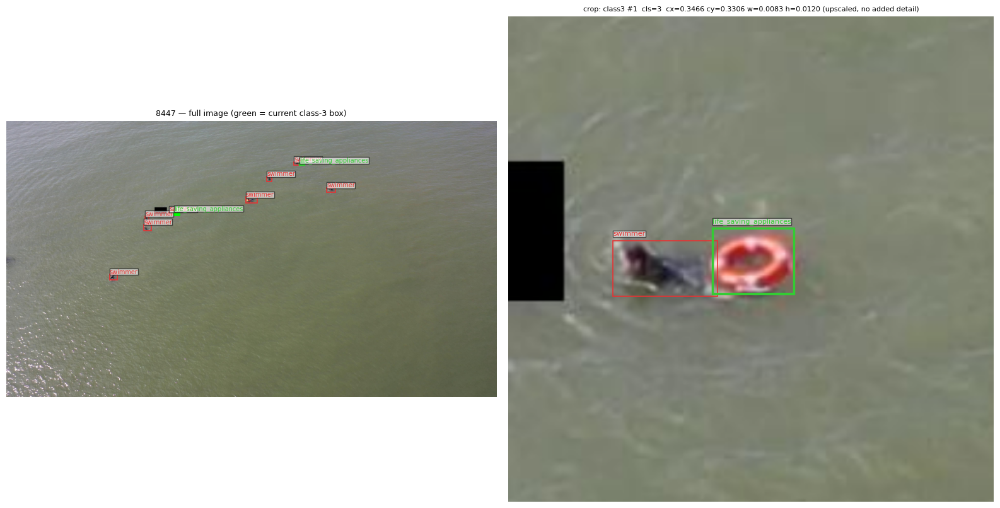

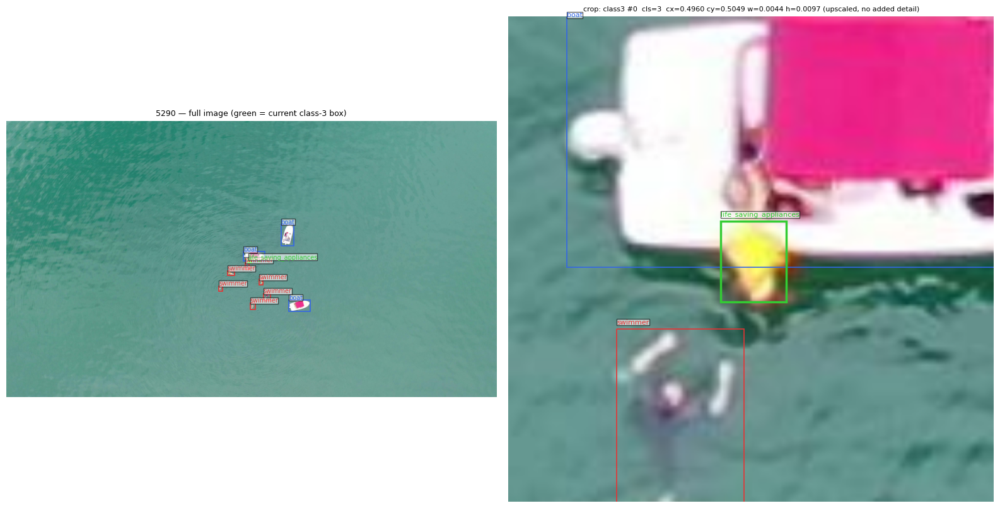

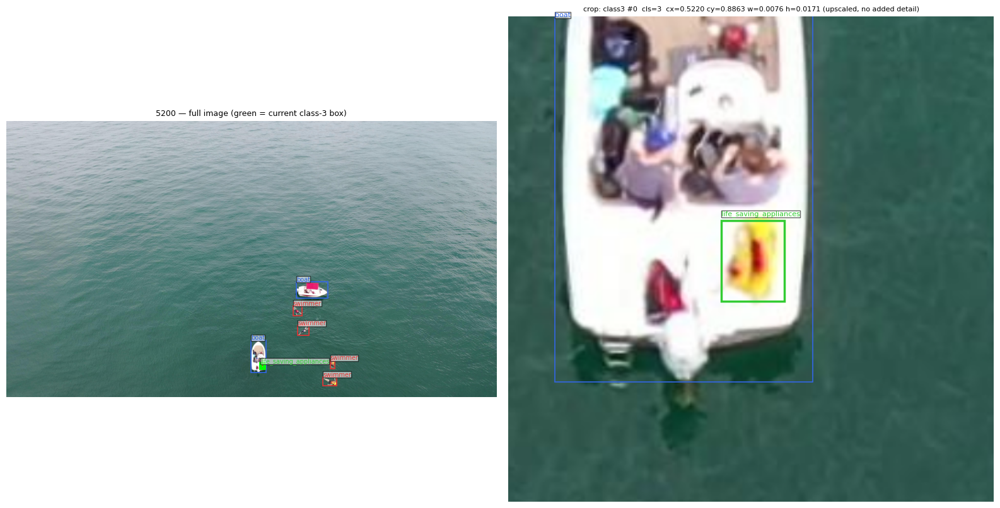

Sample images: ['9801', '5210', '2884', '8500', '8469', '8447', '5290', '5200']
Total class-3 boxes in sample: 11
Records (index, image, box#, cx, cy, w, h):
  0 ('9801', 0, 0.2382, 0.7729, 0.0102, 0.0199)
  1 ('5210', 0, 0.5288, 0.6546, 0.0065, 0.0148)
  2 ('2884', 0, 0.7575, 0.2006, 0.0037, 0.0069)
  3 ('2884', 1, 0.8766, 0.2643, 0.0027, 0.0061)
  4 ('8500', 0, 0.5945, 0.2171, 0.0089, 0.0102)
  5 ('8469', 0, 0.6007, 0.1322, 0.007, 0.0106)
  6 ('8469', 1, 0.3428, 0.3454, 0.0086, 0.012)
  7 ('8447', 0, 0.603, 0.1537, 0.0091, 0.0083)
  8 ('8447', 1, 0.3466, 0.3306, 0.0083, 0.012)
  9 ('5290', 0, 0.496, 0.5049, 0.0044, 0.0097)
  10 ('5200', 0, 0.522, 0.8863, 0.0076, 0.0171)


In [18]:
import random
import cv2
import matplotlib.pyplot as plt

TRAIN_IMAGES = DATASET_DIR / "images" / "train"
TRAIN_LABELS = DATASET_DIR / "labels" / "train"
train_img_map = {p.stem: p for p in TRAIN_IMAGES.glob("*") if p.is_file()}

train_with_gt3 = sorted(
    lbl.stem for lbl in TRAIN_LABELS.glob("*.txt")
    if any(int(float(l.split()[0])) == TARGET
           for l in lbl.read_text(encoding="utf-8").splitlines() if l.strip())
)

random.seed(42)
sample = random.sample(train_with_gt3, 8)

COLORS = {0: (0.9, 0.2, 0.2), 1: (0.2, 0.4, 0.9), 2: (1.0, 0.6, 0.0),
          3: (0.2, 0.8, 0.2), 4: (0.6, 0.2, 0.9)}

def read_boxes(stem):
    out = []
    for line in (TRAIN_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        cx, cy, w, h = map(float, p[1:5])
        out.append((cls, cx, cy, w, h))
    return out

records = []

for stem in sample:
    img = cv2.cvtColor(cv2.imread(str(train_img_map[stem])), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    boxes = read_boxes(stem)
    c3_boxes = [b for b in boxes if b[0] == TARGET]

    for bi, (cls, cx, cy, w, h) in enumerate(c3_boxes):
        tx1, ty1, tx2, ty2 = to_xyxy(cx, cy, w, h, W, H)
        records.append((stem, bi, round(cx, 4), round(cy, 4), round(w, 4), round(h, 4)))

        bw, bh = tx2 - tx1, ty2 - ty1
        pad = 3 * max(bw, bh, 8)
        cx0, cy0 = (tx1 + tx2) / 2, (ty1 + ty2) / 2
        x1 = max(0, int(cx0 - pad)); x2 = min(W, int(cx0 + pad))
        y1 = max(0, int(cy0 - pad)); y2 = min(H, int(cy0 + pad))
        if x2 <= x1: x2 = min(W, x1 + 2)
        if y2 <= y1: y2 = min(H, y1 + 2)

        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        axes[0].imshow(img)
        for (c, cx2, cy2, w2, h2) in boxes:
            x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
            col = COLORS.get(c, (0, 0, 0))
            lw = 2.5 if c == TARGET else 1.2
            axes[0].add_patch(plt.Rectangle((x1b, y1b), x2b - x1b, y2b - y1b,
                              fill=False, edgecolor=col, linewidth=lw))
            axes[0].text(x1b, max(0, y1b - 4), model.names[c], color=col, fontsize=7,
                         bbox=dict(facecolor="white", alpha=0.6, pad=0))
        axes[0].add_patch(plt.Rectangle((tx1, ty1), tx2 - tx1, ty2 - ty1,
                          fill=False, edgecolor=(0, 1, 0), linewidth=3.5))
        axes[0].set_title("%s — full image (green = current class-3 box)" % stem, fontsize=9)
        axes[0].axis("off")

        crop = cv2.resize(img[y1:y2, x1:x2], (400, 400), interpolation=cv2.INTER_LINEAR)
        axes[1].imshow(crop)
        sx = 400.0 / (x2 - x1); sy = 400.0 / (y2 - y1)
        for (c, cx2, cy2, w2, h2) in boxes:
            x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
            if x2b < x1 or x1b > x2 or y2b < y1 or y1b > y2:
                continue
            px1, py1 = (x1b - x1) * sx, (y1b - y1) * sy
            px2, py2 = (x2b - x1) * sx, (y2b - y1) * sy
            col = COLORS.get(c, (0, 0, 0))
            lw = 2.5 if c == TARGET else 1.2
            axes[1].add_patch(plt.Rectangle((px1, py1), px2 - px1, py2 - py1,
                              fill=False, edgecolor=col, linewidth=lw))
            axes[1].text(px1, max(0, py1 - 4), model.names[c], color=col, fontsize=8,
                         bbox=dict(facecolor="white", alpha=0.6, pad=0))
        axes[1].set_title("crop: class3 #%d  cls=%d  cx=%.4f cy=%.4f w=%.4f h=%.4f (upscaled, no added detail)"
                          % (bi, cls, cx, cy, w, h), fontsize=8)
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

print("Sample images:", sample)
print("Total class-3 boxes in sample:", len(records))
print("Records (index, image, box#, cx, cy, w, h):")
for i, r in enumerate(records):
    print("  %d %s" % (i, r))

## Train-label audit — full-image context and model class-confusion

**Purpose.** Determine whether visible life-saving appliances in the training set are
missing annotations or mislabeled as another class (mainly `swimmer` or `buoy`), and
inspect cases where the trained model predicts a different class over a class-3 object.

**What is inspected.** A reproducible sample of 16 training images that contain
`life_saving_appliances` ground-truth boxes (seed = 7). For each image we show the full
frame and enlarged crops around each class-3 box with surrounding context.

**Ground truth vs predictions.** Ground-truth boxes come from the dataset labels and
are drawn as solid rectangles labeled `GT:<class>`. Model predictions come from
`YOLO(best.pt)` at conf 0.25 and are drawn as dashed rectangles labeled `<class> <conf>`.
Solid vs dashed keeps the two visually distinct so they cannot be confused.

**Evidence collected.** Per-image ground-truth class counts and prediction class counts,
the full frames, and class-3 crops with context. A dashed box over an unlabeled object,
or a dashed `swimmer`/`buoy` box over a class-3 box, is only a *candidate* for a missing
annotation or a mislabel — visual confirmation is required.

**Limits.** This is a visual audit of a small sample. Model predictions do not by
themselves prove an annotation is wrong or missing; they only point where to look. It
cannot quantify missing annotations across the whole dataset, and it does not modify
labels or retrain.

Sample size: 16
Sample images: ['8550', '583', '9021', '3086', '4834', '9671', '5192', '8593', '9743', '3110', '9642', '8438', '3040', '5184', '9209', '9118']

Per-image GT and prediction class counts:
  8550  GT={0: 8, 3: 2, 4: 1}  PRED={0: 10, 4: 1}
  583  GT={0: 7, 2: 1, 3: 2}  PRED={0: 8, 1: 1}
  9021  GT={0: 3, 1: 1, 2: 1, 3: 1}  PRED={0: 5, 1: 1, 2: 1}
  3086  GT={0: 6, 1: 1, 3: 1, 4: 1}  PRED={0: 8, 1: 1, 4: 1}
  4834  GT={0: 2, 3: 1}  PRED={0: 2}
  9671  GT={0: 10, 1: 2, 3: 1, 4: 1}  PRED={0: 11, 1: 2, 4: 1}
  5192  GT={0: 4, 1: 2, 3: 1}  PRED={0: 4, 1: 2}
  8593  GT={0: 9, 1: 1, 3: 2, 4: 1}  PRED={0: 9, 1: 1, 4: 1}
  9743  GT={0: 5, 3: 1, 4: 1}  PRED={0: 5, 4: 1}
  3110  GT={0: 1, 3: 1, 4: 1}  PRED={0: 1, 4: 1}
  9642  GT={0: 10, 1: 2, 3: 1, 4: 1}  PRED={0: 11, 1: 2, 4: 1}
  8438  GT={0: 8, 1: 1, 3: 2}  PRED={0: 8, 1: 1}
  3040  GT={0: 10, 3: 3}  PRED={0: 5, 1: 1}
  5184  GT={0: 4, 1: 3, 3: 1}  PRED={0: 4, 1: 3}
  9209  GT={0: 3, 1: 2, 2: 1, 3: 1}  PRED={0: 2, 1: 2, 2: 1}
  91

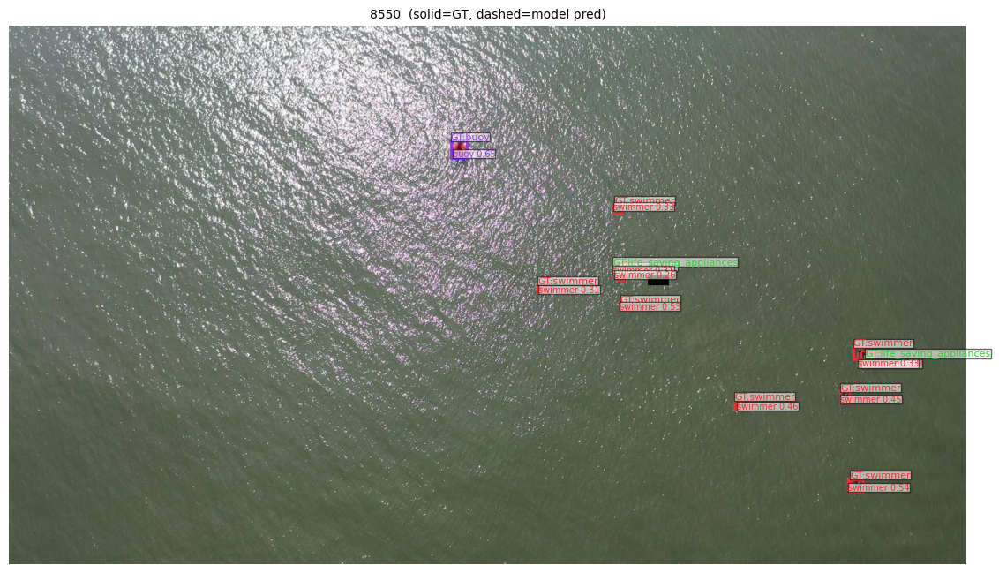

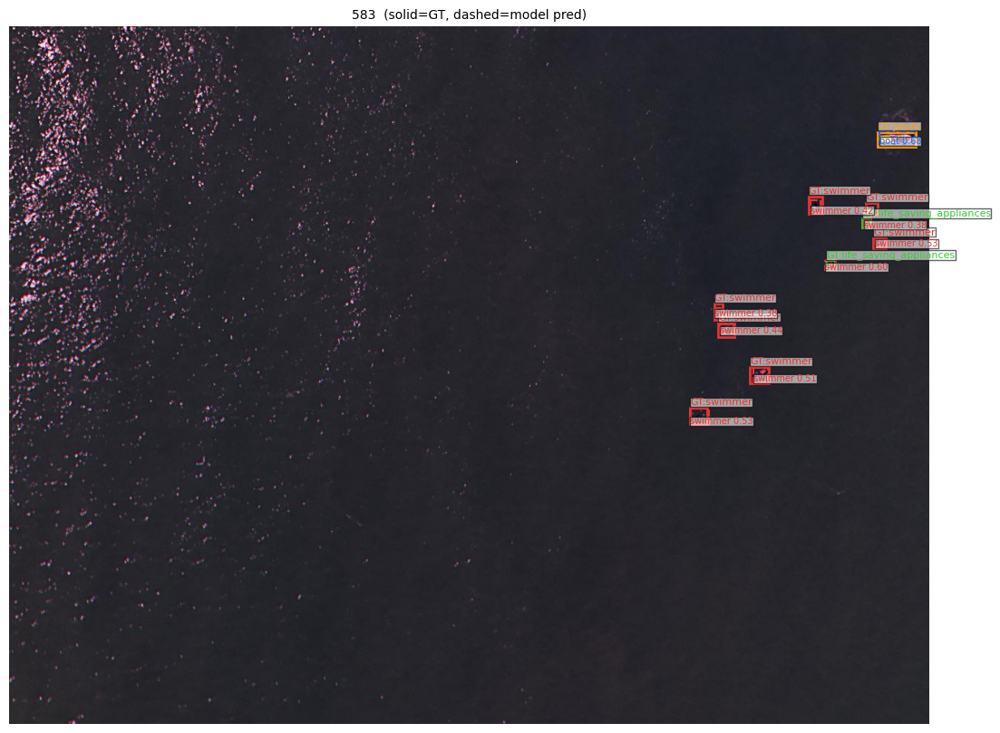

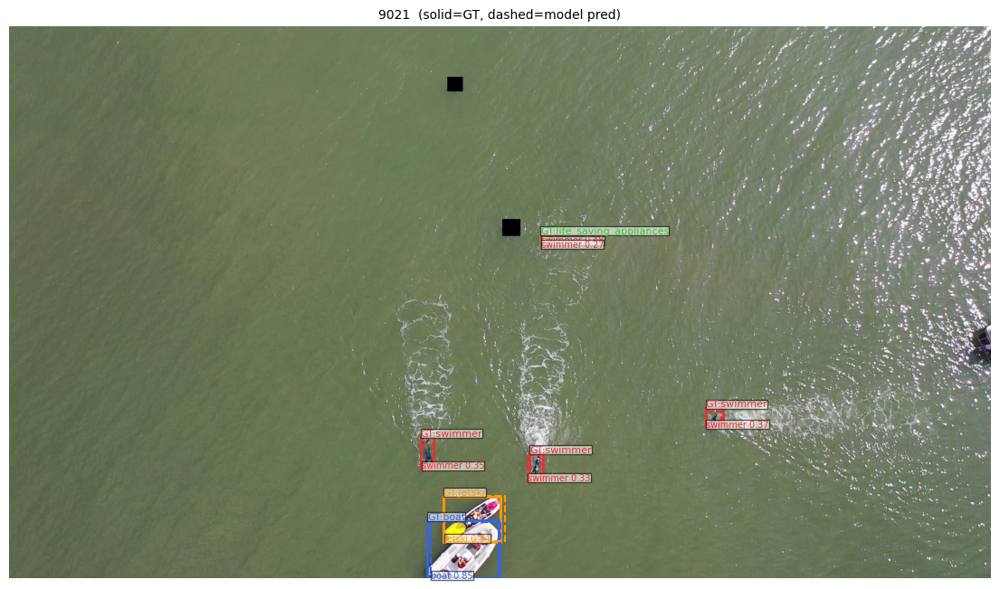

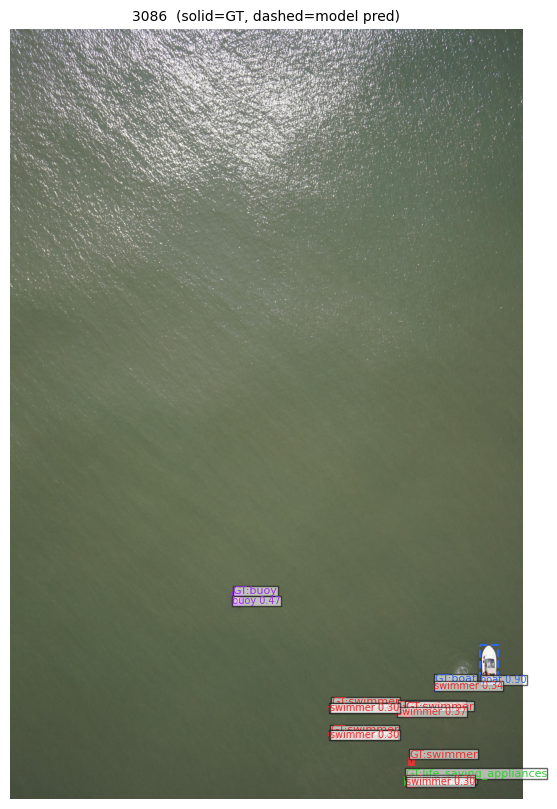

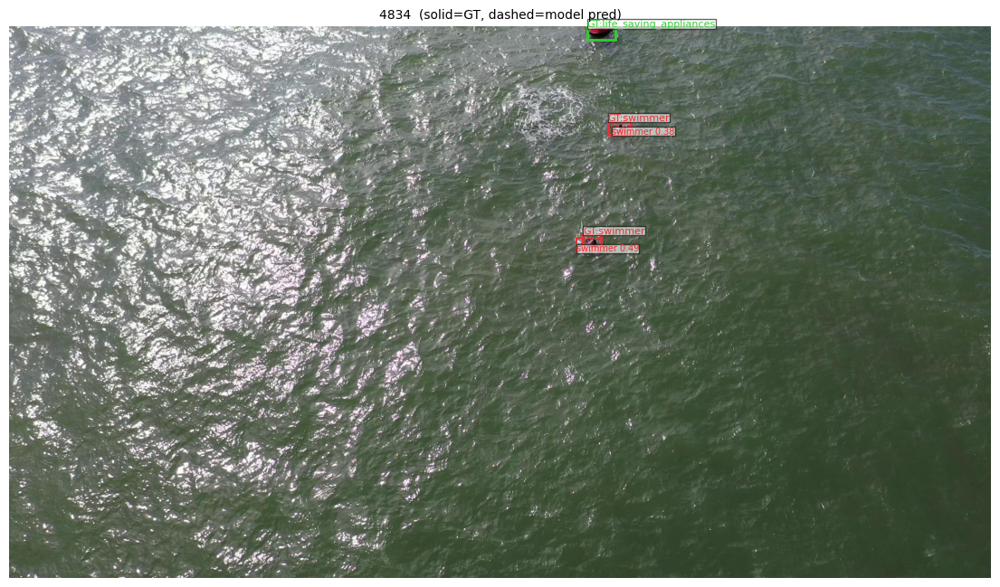

...

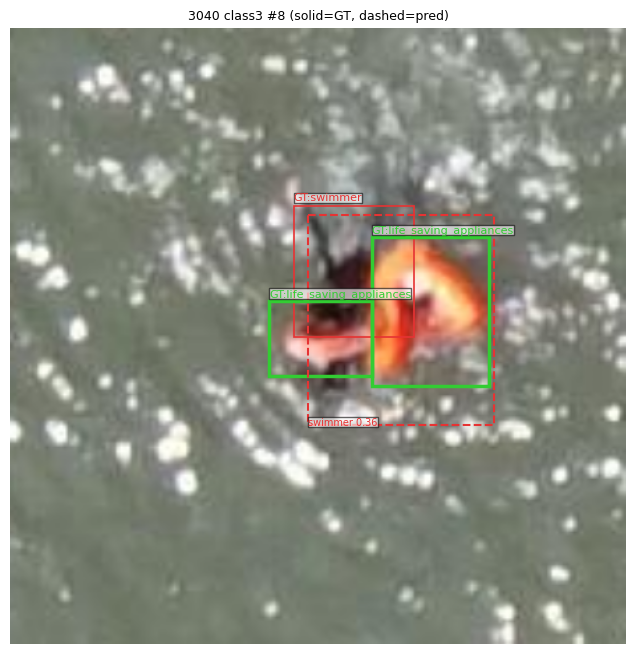

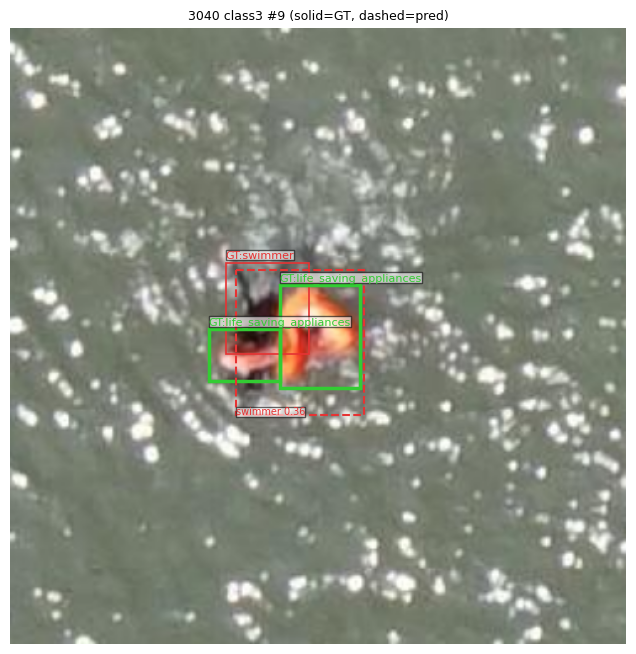

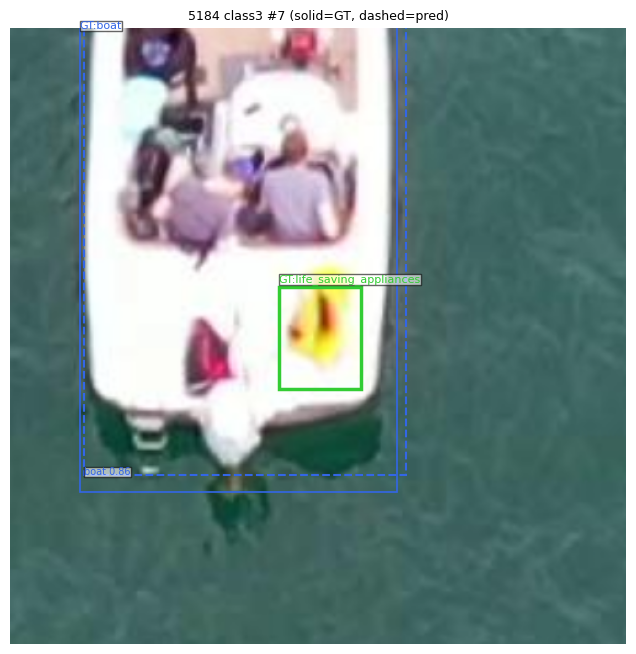

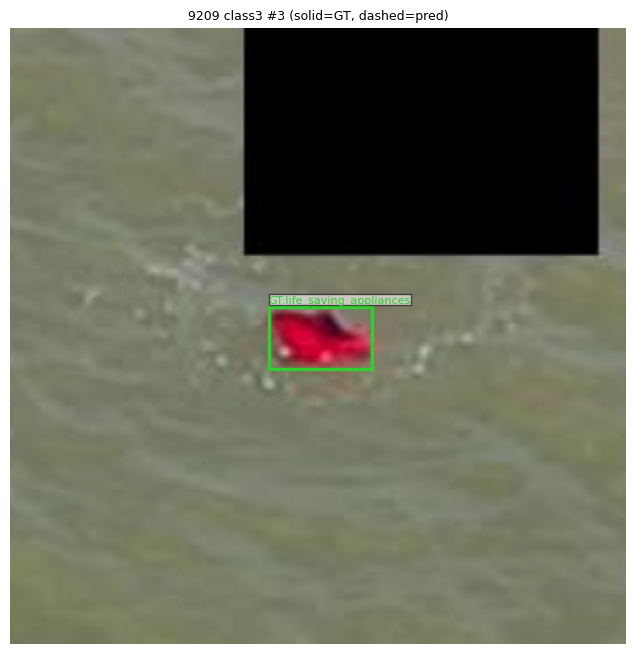

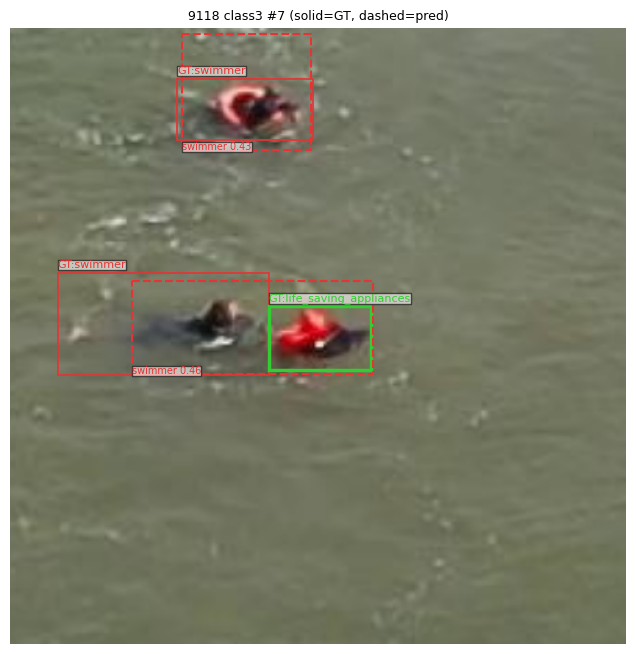

In [19]:
import random
from collections import Counter
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# ---- constants and helpers (self-contained / idempotent; safe to re-run) ----
DATASET_DIR = Path("E:/lifeguardDron/data_prepared/detection/SeaDronesSee_ODv2")
TRAIN_IMAGES = DATASET_DIR / "images" / "train"
TRAIN_LABELS = DATASET_DIR / "labels" / "train"
CHECKPOINT = Path("E:/lifeguardDron/runs/detect/seadrones_smoke_test/weights/best.pt")
TARGET = 3
NAMES = {0: "swimmer", 1: "boat", 2: "jetski", 3: "life_saving_appliances", 4: "buoy"}
COLORS = {0: (0.9, 0.2, 0.2), 1: (0.2, 0.4, 0.9), 2: (1.0, 0.6, 0.0),
          3: (0.2, 0.8, 0.2), 4: (0.6, 0.2, 0.9)}

def to_xyxy(cx, cy, w, h, img_w, img_h):
    return (cx - w/2)*img_w, (cy - h/2)*img_h, (cx + w/2)*img_w, (cy + h/2)*img_h

def iou(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    iw = max(0.0, x2 - x1); ih = max(0.0, y2 - y1)
    inter = iw * ih
    aa = (a[2]-a[0])*(a[3]-a[1]); bb = (b[2]-b[0])*(b[3]-b[1])
    return inter / (aa + bb - inter + 1e-9)

def read_boxes(stem):
    out = []
    for line in (TRAIN_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        cx, cy, w, h = map(float, p[1:5])
        out.append((cls, cx, cy, w, h))
    return out

train_img_map = {p.stem: p for p in TRAIN_IMAGES.glob("*") if p.is_file()}

# ---- model (reuse if already loaded, else load) ----
if "model" not in globals():
    from ultralytics import YOLO
    model = YOLO(str(CHECKPOINT))

# ---- reproducible sample ----
random.seed(7)
candidate = sorted(
    lbl.stem for lbl in TRAIN_LABELS.glob("*.txt")
    if any(int(float(l.split()[0])) == TARGET
           for l in lbl.read_text(encoding="utf-8").splitlines() if l.strip())
)
AUDIT_SAMPLE = random.sample(candidate, min(16, len(candidate)))
print("Sample size:", len(AUDIT_SAMPLE))
print("Sample images:", AUDIT_SAMPLE)

# ---- inference (per-image, graceful on missing/unreadable/failed) ----
preds = {}   # stem -> list of (cls, conf, xyxy)
for stem in AUDIT_SAMPLE:
    ip = train_img_map.get(stem)
    if ip is None:
        print("MISSING image file, skipping:", stem); continue
    if cv2.imread(str(ip)) is None:
        print("UNREADABLE image, skipping:", stem); continue
    try:
        r = next(model.predict(source=str(ip), conf=0.25, iou=0.6, imgsz=640, device=0,
                              save=False, save_txt=False, plots=False, verbose=False,
                              stream=True))
    except Exception as e:
        print("INFERENCE error for", stem, ":", e); continue
    out = []
    if r.boxes is not None and len(r.boxes) > 0:
        xyxy = r.boxes.xyxy.cpu().numpy()
        conf = r.boxes.conf.cpu().numpy()
        cls = r.boxes.cls.cpu().numpy().astype(int)
        for i in range(len(conf)):
            out.append((int(cls[i]), float(conf[i]), tuple(xyxy[i])))
    preds[stem] = out

# ---- per-image GT and prediction class counts ----
print("\nPer-image GT and prediction class counts:")
for stem in AUDIT_SAMPLE:
    gt_counts = Counter(c for (c, *_rest) in read_boxes(stem))
    pred_counts = Counter(pc for (pc, cf, bb) in preds.get(stem, []))
    print("  %s  GT=%s  PRED=%s" % (stem, dict(sorted(gt_counts.items())),
                                    dict(sorted(pred_counts.items()))))

# ---- full images (GT solid, predictions dashed) ----
for stem in AUDIT_SAMPLE:
    ip = train_img_map.get(stem)
    if ip is None:
        continue
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    fig, ax = plt.subplots(figsize=(14, 10))
    ax.imshow(img)
    for (c, cx, cy, w, h) in read_boxes(stem):
        x1, y1, x2, y2 = to_xyxy(cx, cy, w, h, W, H)
        col = COLORS.get(c, (0, 0, 0))
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=col, linewidth=2.0))
        ax.text(x1, max(0, y1-4), "GT:" + NAMES[c], color=col, fontsize=8,
                bbox=dict(facecolor="white", alpha=0.6, pad=0))
    for (c, cf, (x1, y1, x2, y2)) in preds.get(stem, []):
        col = COLORS.get(c, (0, 0, 0))
        ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor=col,
                     linewidth=1.5, linestyle="--"))
        ax.text(x1, y2, "%s %.2f" % (NAMES[c], cf), color=col, fontsize=7,
                bbox=dict(facecolor="white", alpha=0.6, pad=0))
    ax.set_title("%s  (solid=GT, dashed=model pred)" % stem, fontsize=10)
    ax.axis("off")
    plt.show()

# ---- enlarged crops around class-3 boxes (with context) ----
for stem in AUDIT_SAMPLE:
    ip = train_img_map.get(stem)
    if ip is None:
        continue
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    boxes = read_boxes(stem)
    for bi, (c, cx, cy, w, h) in enumerate(boxes):
        if c != TARGET:
            continue
        tx1, ty1, tx2, ty2 = to_xyxy(cx, cy, w, h, W, H)
        bw, bh = tx2 - tx1, ty2 - ty1
        pad = 3 * max(bw, bh, 8)
        cx0, cy0 = (tx1 + tx2) / 2, (ty1 + ty2) / 2
        x1 = max(0, int(cx0 - pad)); x2 = min(W, int(cx0 + pad))
        y1 = max(0, int(cy0 - pad)); y2 = min(H, int(cy0 + pad))
        if x2 <= x1: x2 = min(W, x1 + 2)
        if y2 <= y1: y2 = min(H, y1 + 2)

        crop = cv2.resize(img[y1:y2, x1:x2], (500, 500), interpolation=cv2.INTER_LINEAR)
        fig, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(crop)
        sx = 500.0 / (x2 - x1); sy = 500.0 / (y2 - y1)
        for (c2, cx2, cy2, w2, h2) in boxes:
            x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
            if x2b < x1 or x1b > x2 or y2b < y1 or y1b > y2:
                continue
            px1, py1 = (x1b - x1)*sx, (y1b - y1)*sy
            px2, py2 = (x2b - x1)*sx, (y2b - y1)*sy
            col = COLORS.get(c2, (0, 0, 0))
            lw = 2.5 if c2 == TARGET else 1.2
            ax.add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                         edgecolor=col, linewidth=lw))
            ax.text(px1, max(0, py1-4), "GT:" + NAMES[c2], color=col, fontsize=8,
                    bbox=dict(facecolor="white", alpha=0.6, pad=0))
        for (pc, pcf, (x1b, y1b, x2b, y2b)) in preds.get(stem, []):
            if x2b < x1 or x1b > x2 or y2b < y1 or y1b > y2:
                continue
            px1, py1 = (x1b - x1)*sx, (y1b - y1)*sy
            px2, py2 = (x2b - x1)*sx, (y2b - y1)*sy
            col = COLORS.get(pc, (0, 0, 0))
            ax.add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                         edgecolor=col, linewidth=1.5, linestyle="--"))
            ax.text(px1, py2, "%s %.2f" % (NAMES[pc], pcf), color=col, fontsize=7,
                    bbox=dict(facecolor="white", alpha=0.6, pad=0))
        ax.set_title("%s class3 #%d (solid=GT, dashed=pred)" % (stem, bi), fontsize=9)
        ax.axis("off")
        plt.show()

## Suspected incorrect class-3 bounding boxes — record for review

Two `life_saving_appliances` boxes were flagged during visual inspection: the box
appears to cover water while the visible life-saving equipment sits nearby, outside
the box. These are **suspected** incorrect annotations, not confirmed errors — they
need a second look before any correction is proposed.

The cell below records each case (image, box index, normalized coordinates, reason)
and shows the full image plus an enlarged crop, with the suspected box drawn in red.
No labels are modified.

In [20]:
# Reuses helpers from the previous cell (TARGET, NAMES, COLORS, to_xyxy,
# read_boxes, train_img_map). Run the previous cell first if needed.

SUSPECTS = [
    # (image_stem, class3_box_index_0_based)
    ("<IMAGE_STEM_1>", 0),
    ("<IMAGE_STEM_2>", 0),
]
REASON = "box appears to cover water instead of the visible life-saving equipment"

import cv2
import matplotlib.pyplot as plt

for (stem, bi) in SUSPECTS:
    ip = train_img_map.get(stem)
    if ip is None:
        print("MISSING image:", stem); continue

    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    c3_boxes = [(c, cx, cy, w, h) for (c, cx, cy, w, h) in read_boxes(stem) if c == TARGET]

    if not (0 <= bi < len(c3_boxes)):
        print("box index %d out of range for %s (has %d class-3 boxes)" % (bi, stem, len(c3_boxes)))
        continue

    (c, cx, cy, w, h) = c3_boxes[bi]
    tx1, ty1, tx2, ty2 = to_xyxy(cx, cy, w, h, W, H)

    print("SUSPECTED INCORRECT BOX")
    print("  image:", stem, "  box_index:", bi)
    print("  normalized (cx, cy, w, h) = (%.4f, %.4f, %.4f, %.4f)" % (cx, cy, w, h))
    print("  reason:", REASON)

    bw, bh = tx2 - tx1, ty2 - ty1
    pad = 4 * max(bw, bh, 16)
    cx0, cy0 = (tx1 + tx2) / 2, (ty1 + ty2) / 2
    x1 = max(0, int(cx0 - pad)); x2 = min(W, int(cx0 + pad))
    y1 = max(0, int(cy0 - pad)); y2 = min(H, int(cy0 + pad))
    if x2 <= x1: x2 = min(W, x1 + 2)
    if y2 <= y1: y2 = min(H, y1 + 2)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # left: full image with all GT boxes, suspected box in red
    axes[0].imshow(img)
    for (c2, cx2, cy2, w2, h2) in read_boxes(stem):
        x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
        col = COLORS.get(c2, (0, 0, 0))
        axes[0].add_patch(plt.Rectangle((x1b, y1b), x2b-x1b, y2b-y1b, fill=False,
                          edgecolor=col, linewidth=1.3))
        axes[0].text(x1b, max(0, y1b-4), NAMES[c2], color=col, fontsize=7,
                     bbox=dict(facecolor="white", alpha=0.6, pad=0))
    axes[0].add_patch(plt.Rectangle((tx1, ty1), tx2-tx1, ty2-ty1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))
    axes[0].set_title("%s full image (red = suspected box)" % stem, fontsize=9)
    axes[0].axis("off")

    # right: enlarged crop (interpolation; no added detail)
    crop = cv2.resize(img[y1:y2, x1:x2], (500, 500), interpolation=cv2.INTER_LINEAR)
    axes[1].imshow(crop)
    sx = 500.0 / (x2 - x1); sy = 500.0 / (y2 - y1)
    for (c2, cx2, cy2, w2, h2) in read_boxes(stem):
        x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
        if x2b < x1 or x1b > x2 or y2b < y1 or y1b > y2:
            continue
        px1, py1 = (x1b - x1)*sx, (y1b - y1)*sy
        px2, py2 = (x2b - x1)*sx, (y2b - y1)*sy
        col = COLORS.get(c2, (0, 0, 0))
        lw = 2.5 if c2 == TARGET else 1.2
        axes[1].add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                          edgecolor=col, linewidth=lw))
        axes[1].text(px1, max(0, py1-4), NAMES[c2], color=col, fontsize=8,
                     bbox=dict(facecolor="white", alpha=0.6, pad=0))
    # suspected box in red
    px1, py1 = (tx1 - x1)*sx, (ty1 - y1)*sy
    px2, py2 = (tx2 - x1)*sx, (ty2 - y1)*sy
    axes[1].add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))
    axes[1].set_title("%s class3 #%d zoom (red = suspected box; upscaled, no added detail)"
                      % (stem, bi), fontsize=8)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

MISSING image: <IMAGE_STEM_1>
MISSING image: <IMAGE_STEM_2>


## Three suspected incorrect class-3 bounding boxes — record for review

Three `life_saving_appliances` boxes were flagged during visual inspection: the box
appears to cover water while the visible life-saving equipment sits nearby, outside
the box. These are **suspected** incorrect annotations, not confirmed errors — they
need a second look before any correction is proposed.

Selected cases (resolved by image stem + class-3 box index):
- 8438 #0
- 8438 #1
- 9209 #0

The cell below records each case (image, box index, normalized coordinates, reason)
and shows the full image plus an enlarged crop, with the suspected box drawn in red.
No labels are modified.

SUSPECTED INCORRECT BOX
  image: 8438   box_index: 0
  normalized (cx, cy, w, h) = (0.6077, 0.4542, 0.0091, 0.0093)
  reason: box appears to cover water instead of the visible life-saving equipment


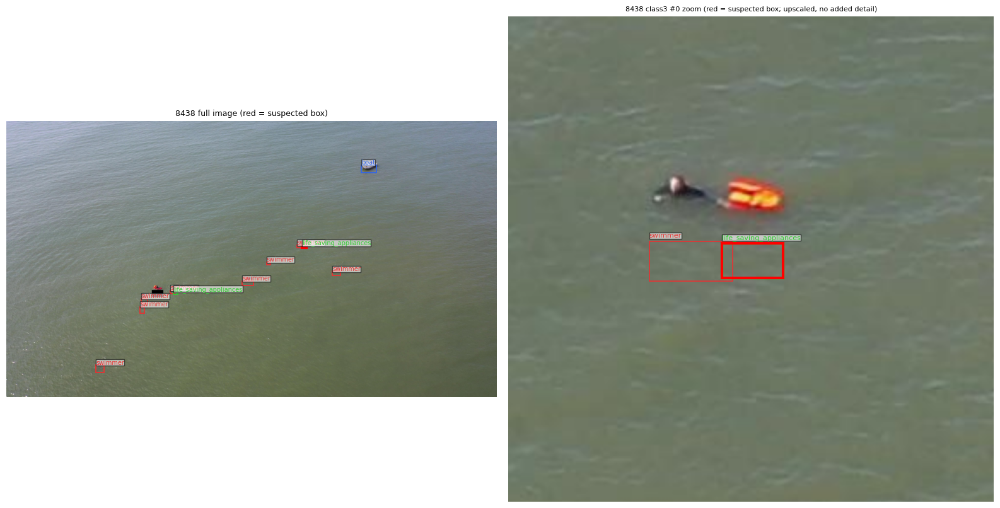

SUSPECTED INCORRECT BOX
  image: 8438   box_index: 1
  normalized (cx, cy, w, h) = (0.3456, 0.6220, 0.0089, 0.0106)
  reason: box appears to cover water instead of the visible life-saving equipment


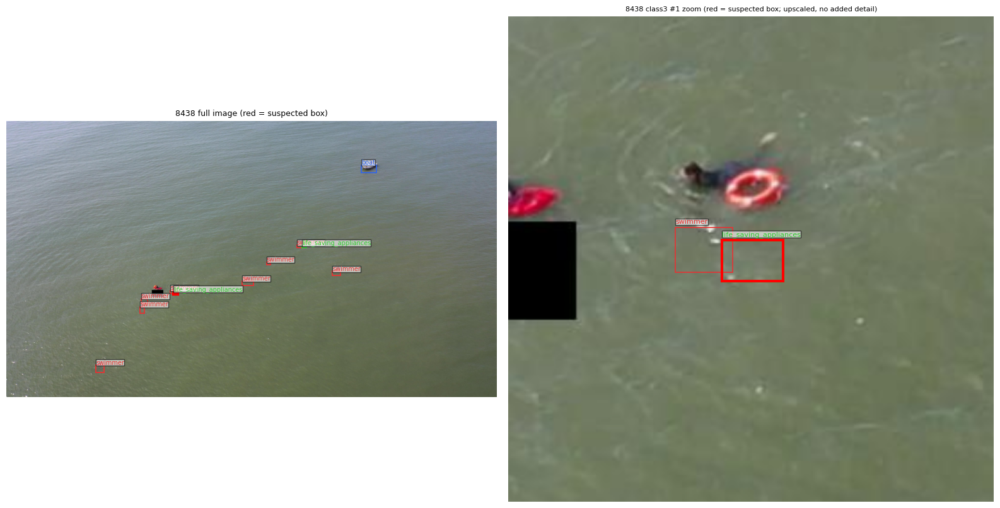

SUSPECTED INCORRECT BOX
  image: 9209   box_index: 0
  normalized (cx, cy, w, h) = (0.6232, 0.4130, 0.0078, 0.0083)
  reason: box appears to cover water instead of the visible life-saving equipment


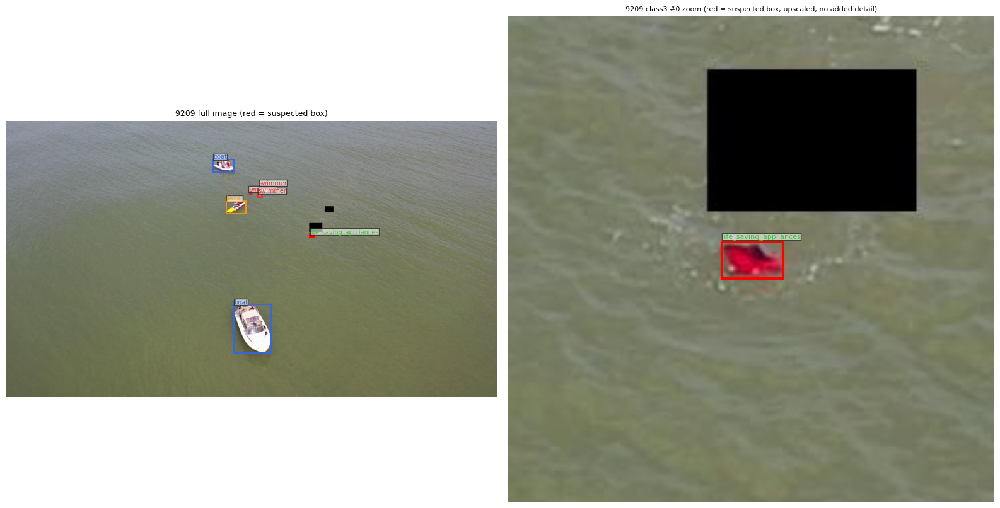

In [21]:
# Reuses helpers from the previous cell (TARGET, NAMES, COLORS, to_xyxy,
# read_boxes, train_img_map).

SUSPECTS = [
    ("8438", 0),
    ("8438", 1),
    ("9209", 0),
]
REASON = "box appears to cover water instead of the visible life-saving equipment"

import cv2
import matplotlib.pyplot as plt

for (stem, bi) in SUSPECTS:
    ip = train_img_map.get(stem)
    if ip is None:
        print("MISSING image:", stem); continue

    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    c3_boxes = [(c, cx, cy, w, h) for (c, cx, cy, w, h) in read_boxes(stem) if c == TARGET]

    if not (0 <= bi < len(c3_boxes)):
        print("box index %d out of range for %s (has %d class-3 boxes)"
              % (bi, stem, len(c3_boxes)))
        continue

    (c, cx, cy, w, h) = c3_boxes[bi]
    tx1, ty1, tx2, ty2 = to_xyxy(cx, cy, w, h, W, H)

    print("SUSPECTED INCORRECT BOX")
    print("  image:", stem, "  box_index:", bi)
    print("  normalized (cx, cy, w, h) = (%.4f, %.4f, %.4f, %.4f)" % (cx, cy, w, h))
    print("  reason:", REASON)

    bw, bh = tx2 - tx1, ty2 - ty1
    pad = 4 * max(bw, bh, 16)
    cx0, cy0 = (tx1 + tx2) / 2, (ty1 + ty2) / 2
    x1 = max(0, int(cx0 - pad)); x2 = min(W, int(cx0 + pad))
    y1 = max(0, int(cy0 - pad)); y2 = min(H, int(cy0 + pad))
    if x2 <= x1: x2 = min(W, x1 + 2)
    if y2 <= y1: y2 = min(H, y1 + 2)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # left: full image, all GT boxes, suspected box in red
    axes[0].imshow(img)
    for (c2, cx2, cy2, w2, h2) in read_boxes(stem):
        x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
        col = COLORS.get(c2, (0, 0, 0))
        axes[0].add_patch(plt.Rectangle((x1b, y1b), x2b-x1b, y2b-y1b, fill=False,
                          edgecolor=col, linewidth=1.3))
        axes[0].text(x1b, max(0, y1b-4), NAMES[c2], color=col, fontsize=7,
                     bbox=dict(facecolor="white", alpha=0.6, pad=0))
    axes[0].add_patch(plt.Rectangle((tx1, ty1), tx2-tx1, ty2-ty1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))
    axes[0].set_title("%s full image (red = suspected box)" % stem, fontsize=9)
    axes[0].axis("off")

    # right: enlarged crop (interpolation; no added detail)
    crop = cv2.resize(img[y1:y2, x1:x2], (500, 500), interpolation=cv2.INTER_LINEAR)
    axes[1].imshow(crop)
    sx = 500.0 / (x2 - x1); sy = 500.0 / (y2 - y1)
    for (c2, cx2, cy2, w2, h2) in read_boxes(stem):
        x1b, y1b, x2b, y2b = to_xyxy(cx2, cy2, w2, h2, W, H)
        if x2b < x1 or x1b > x2 or y2b < y1 or y1b > y2:
            continue
        px1, py1 = (x1b - x1)*sx, (y1b - y1)*sy
        px2, py2 = (x2b - x1)*sx, (y2b - y1)*sy
        col = COLORS.get(c2, (0, 0, 0))
        lw = 2.5 if c2 == TARGET else 1.2
        axes[1].add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                          edgecolor=col, linewidth=lw))
        axes[1].text(px1, max(0, py1-4), NAMES[c2], color=col, fontsize=8,
                     bbox=dict(facecolor="white", alpha=0.6, pad=0))
    px1, py1 = (tx1 - x1)*sx, (ty1 - y1)*sy
    px2, py2 = (tx2 - x1)*sx, (ty2 - y1)*sy
    axes[1].add_patch(plt.Rectangle((px1, py1), px2-px1, py2-py1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))
    axes[1].set_title("%s class3 #%d zoom (red = suspected box; upscaled, no added detail)"
                      % (stem, bi), fontsize=8)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

## Correction review for three flagged class-3 boxes

Three `life_saving_appliances` boxes were visually rechecked and flagged as
**suspected incorrect annotations**:

- `8438 #0` — box appears to cover water instead of the life-saving equipment.
- `8438 #1` — box appears to cover water instead of the life-saving equipment.
- `9209 #0` — box appears to cover a different object, not a life-saving appliance.

The cell below (1) prints each original normalized `(cx, cy, w, h)`, (2) shows the
full image and a zoomed crop with the original box in red, (3) lets you add a
corrected `(cx, cy, w, h)` and optional new class in `DRAFT_CORRECTIONS` only after
you identify the actual equipment, (4) shows a before/after preview (red = original,
green dashed = proposed), and (5) writes a separate review file only when
`SAVE_REVIEW = True`. Original labels are never modified, and no box is moved or
relabeled automatically. If the equipment cannot be identified clearly, leave that
case out of `DRAFT_CORRECTIONS`.

=== Original flagged boxes (normalized) ===
  8438 #0  cls=3  (cx, cy, w, h) = (0.6077, 0.4542, 0.0091, 0.0093)
  8438 #1  cls=3  (cx, cy, w, h) = (0.3456, 0.6220, 0.0089, 0.0106)
  9209 #0  cls=3  (cx, cy, w, h) = (0.6232, 0.4130, 0.0078, 0.0083)

=== Flagged boxes (original in red) ===


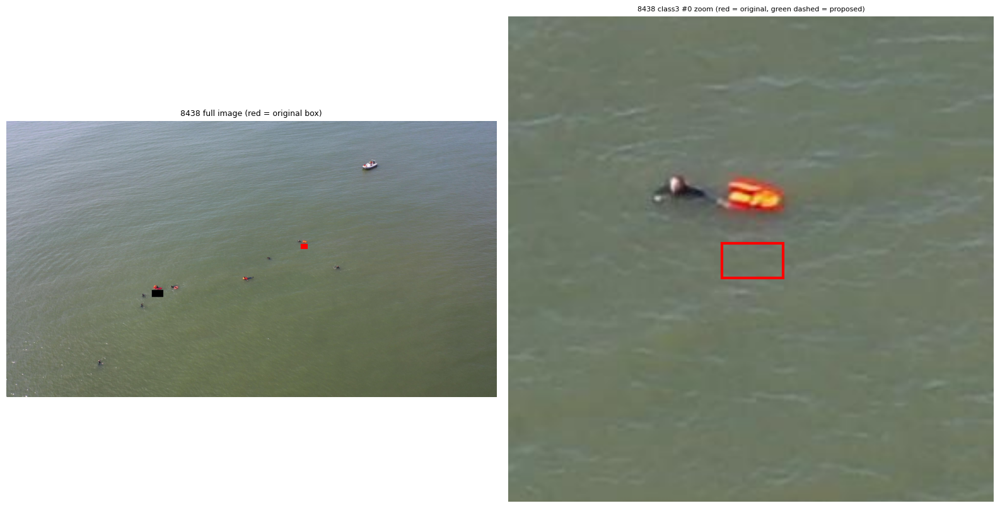

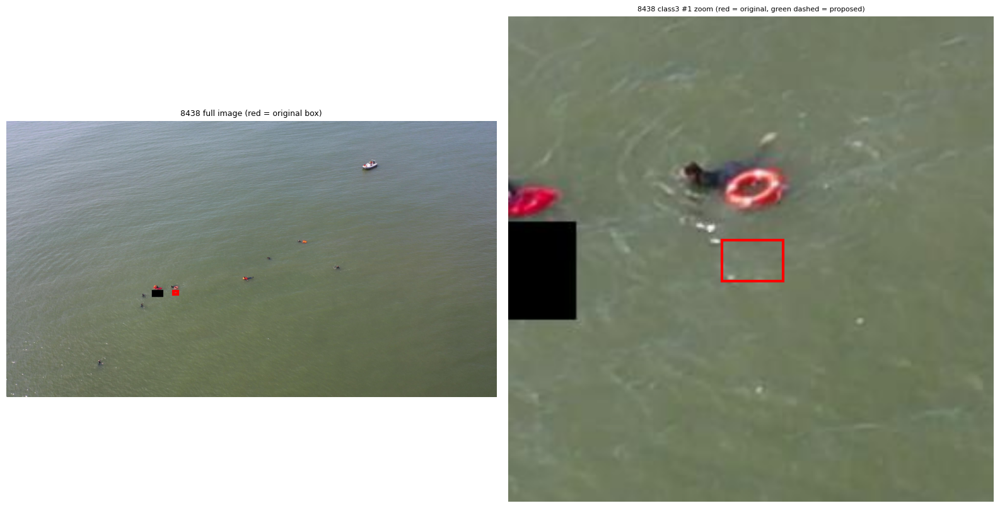

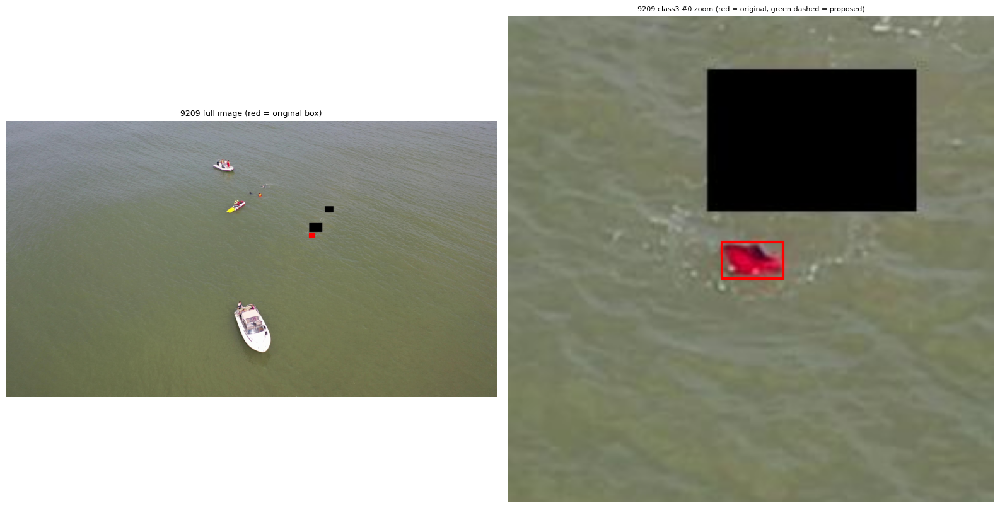


No draft corrections yet. Inspect the crops above, identify the actual
equipment location, then add rows to DRAFT_CORRECTIONS and re-run to preview.


In [22]:
import cv2
import json
import matplotlib.pyplot as plt
from pathlib import Path

# ---- configuration ----
SAVE_REVIEW = False   # set True to write the review file (after you preview)
REVIEW_PATH = Path("E:/lifeguardDron/reports/ponytail_label_review/flagged_boxes.json")

FLAGGED = [("8438", 0), ("8438", 1), ("9209", 0)]

# Add proposed corrections ONLY after identifying the actual equipment location in
# the displayed crops. Row format:
#   (stem, box_index, new_cx, new_cy, new_w, new_h, new_class_or_None)
# new_class_or_None=None keeps class 3; set an int to propose a class change.
DRAFT_CORRECTIONS = []

# ---- helpers (reuse TARGET, to_xyxy, TRAIN_LABELS, train_img_map from prior cells) ----
def read_all_boxes(stem):
    out = []
    for line in (TRAIN_LABELS / (stem + ".txt")).read_text(encoding="utf-8").splitlines():
        p = line.split()
        if len(p) < 5:
            continue
        out.append((int(float(p[0])), float(p[1]), float(p[2]), float(p[3]), float(p[4])))
    return out

def c3_boxes(stem):
    return [(c, cx, cy, w, h) for (c, cx, cy, w, h) in read_all_boxes(stem) if c == TARGET]

# ---- 1 + 2: print original normalized coordinates ----
print("=== Original flagged boxes (normalized) ===")
for (stem, bi) in FLAGGED:
    boxes = c3_boxes(stem)
    if not (0 <= bi < len(boxes)):
        print("  %s #%d  OUT OF RANGE (%d class-3 boxes)" % (stem, bi, len(boxes)))
        continue
    (c, cx, cy, w, h) = boxes[bi]
    print("  %s #%d  cls=%d  (cx, cy, w, h) = (%.4f, %.4f, %.4f, %.4f)" % (stem, bi, c, cx, cy, w, h))

# ---- 3: display each flagged box (full image + crop, original in red) ----
def display_box(stem, bi, green=None):
    ip = train_img_map.get(stem)
    if ip is None:
        print("MISSING image:", stem); return
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    boxes = c3_boxes(stem)
    if not (0 <= bi < len(boxes)):
        print("box index %d out of range for %s" % (bi, stem)); return
    (c, cx, cy, w, h) = boxes[bi]
    tx1, ty1, tx2, ty2 = to_xyxy(cx, cy, w, h, W, H)

    bw, bh = tx2 - tx1, ty2 - ty1
    pad = 4 * max(bw, bh, 16)
    cx0, cy0 = (tx1 + tx2) / 2, (ty1 + ty2) / 2
    x1 = max(0, int(cx0 - pad)); x2 = min(W, int(cx0 + pad))
    y1 = max(0, int(cy0 - pad)); y2 = min(H, int(cy0 + pad))
    if x2 <= x1: x2 = min(W, x1 + 2)
    if y2 <= y1: y2 = min(H, y1 + 2)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    axes[0].imshow(img)
    axes[0].add_patch(plt.Rectangle((tx1, ty1), tx2 - tx1, ty2 - ty1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))
    axes[0].set_title("%s full image (red = original box)" % stem, fontsize=9)
    axes[0].axis("off")

    crop = cv2.resize(img[y1:y2, x1:x2], (500, 500), interpolation=cv2.INTER_LINEAR)
    axes[1].imshow(crop)
    sx = 500.0 / (x2 - x1); sy = 500.0 / (y2 - y1)
    px1, py1 = (tx1 - x1) * sx, (ty1 - y1) * sy
    px2, py2 = (tx2 - x1) * sx, (ty2 - y1) * sy
    axes[1].add_patch(plt.Rectangle((px1, py1), px2 - px1, py2 - py1, fill=False,
                      edgecolor=(1, 0, 0), linewidth=3.0))

    if green is not None:
        gx1, gy1, gx2, gy2 = to_xyxy(*green, W, H)
        axes[0].add_patch(plt.Rectangle((gx1, gy1), gx2 - gx1, gy2 - gy1, fill=False,
                          edgecolor=(0, 1, 0), linewidth=2.0, linestyle="--"))
        qx1, qy1 = (gx1 - x1) * sx, (gy1 - y1) * sy
        qx2, qy2 = (gx2 - x1) * sx, (gy2 - y1) * sy
        axes[1].add_patch(plt.Rectangle((qx1, qy1), qx2 - qx1, qy2 - qy1, fill=False,
                          edgecolor=(0, 1, 0), linewidth=2.0, linestyle="--"))

    axes[1].set_title("%s class3 #%d zoom (red = original, green dashed = proposed)" % (stem, bi), fontsize=8)
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

print("\n=== Flagged boxes (original in red) ===")
for (stem, bi) in FLAGGED:
    display_box(stem, bi)

# ---- 4 + 5: before/after preview for any draft corrections ----
if DRAFT_CORRECTIONS:
    print("\n=== Before/after preview (red = original, green dashed = proposed) ===")
    for (stem, bi, ncx, ncy, nw, nh, ncls) in DRAFT_CORRECTIONS:
        print("  %s #%d  ->  proposed (cx, cy, w, h) = (%.4f, %.4f, %.4f, %.4f)  class=%s"
              % (stem, bi, ncx, ncy, nw, nh, ncls if ncls is not None else "3 (unchanged)"))
        display_box(stem, bi, green=(ncx, ncy, nw, nh))
else:
    print("\nNo draft corrections yet. Inspect the crops above, identify the actual")
    print("equipment location, then add rows to DRAFT_CORRECTIONS and re-run to preview.")

# ---- 6: optional save to a separate review file (never touches original labels) ----
if SAVE_REVIEW:
    records = []
    for (stem, bi, ncx, ncy, nw, nh, ncls) in DRAFT_CORRECTIONS:
        boxes = c3_boxes(stem)
        if not (0 <= bi < len(boxes)):
            continue
        (oc, ocx, ocy, ow, oh) = boxes[bi]
        records.append({
            "stem": stem, "box_index": bi,
            "original": {"class": oc, "cx": ocx, "cy": ocy, "w": ow, "h": oh},
            "proposed": {"class": ncls if ncls is not None else oc,
                          "cx": ncx, "cy": ncy, "w": nw, "h": nh},
        })
    REVIEW_PATH.parent.mkdir(parents=True, exist_ok=True)
    if REVIEW_PATH.exists():
        print("REFUSING to overwrite existing review file:", REVIEW_PATH)
    else:
        REVIEW_PATH.write_text(json.dumps(records, indent=2), encoding="utf-8")
        print("Wrote review file:", REVIEW_PATH, "with", len(records), "proposal(s)")

## YOLO11 baseline and next-experiment plan

**Goal.** Establish a reproducible per-class baseline for the current checkpoint and
select the single most defensible improvement experiment.

**Key finding that reframes the baseline.** The saved `best.pt` comes from a **2-epoch
smoke test** (`runs/detect/seadrones_smoke_test/args.yaml`, `epochs: 2`). The model is
not converged, so `life_saving_appliances` recall = 0.0 is not yet evidence of an
irrecoverable problem.

**Hypothesis.** Class 3 is under-represented (923 train boxes vs 37,096 swimmer ≈ 40×),
but the current 2-epoch model confounds under-representation with under-training.
Training duration must be fixed before attributing the failure to imbalance.

**Metrics to compare.** Per-class Precision / Recall / mAP@50 / mAP@50-95, with
`life_saving_appliances` as the primary class of interest.

**Safeguards.** Read-only: verify paths, reuse the saved validation CSV and args.yaml,
do not retrain, do not modify labels or weights, and write any new report only to a
new path with an overwrite guard.

In [24]:
from pathlib import Path
import csv

PROJECT = Path("E:/lifeguardDron")
CHECKPOINT = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "weights" / "best.pt"
DATASET_YAML = PROJECT / "data_prepared" / "detection" / "SeaDronesSee_ODv2" / "dataset.yaml"
ARGS_YAML = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "args.yaml"
RESULTS_CSV = PROJECT / "runs" / "detect" / "seadrones_smoke_test" / "results.csv"
VAL_METRICS_CSV = PROJECT / "reports" / "model_evaluation" / "yolo11n_validation_metrics.csv"

# 1. verify paths
print("=== Paths ===")
for p in (CHECKPOINT, DATASET_YAML, ARGS_YAML, RESULTS_CSV, VAL_METRICS_CSV):
    print("  %-7s %s" % ("OK" if p.exists() else "MISSING", p))

# 2 + 3. saved per-class validation metrics (the baseline table)
print("\n=== Per-class baseline (saved validation CSV) ===")
with open(VAL_METRICS_CSV, encoding="utf-8") as f:
    for row in csv.reader(f):
        print("  " + "  |  ".join(row))

# 4. training configuration from args.yaml
print("\n=== Training config (args.yaml) ===")
keys = ["model", "epochs", "batch", "imgsz", "device", "pretrained", "seed",
        "deterministic", "cls_remap", "conf", "iou", "box", "cls", "dfl",
        "patience", "optimizer", "mosaic", "erasing"]
args = {}
for line in open(ARGS_YAML, encoding="utf-8"):
    line = line.strip()
    if ":" in line and not line.startswith("#"):
        k, v = line.split(":", 1)
        args[k.strip()] = v.strip().strip("'\"")
for k in keys:
    print("  %-14s = %s" % (k, args.get(k, "?")))

# per-epoch timing from results.csv
epochs = []
with open(RESULTS_CSV, encoding="utf-8") as f:
    for row in csv.DictReader(f):
        epochs.append((int(row["epoch"]), float(row["time"])))
if len(epochs) >= 2:
    per_epoch = epochs[-1][1] - epochs[-2][1]
    print("  time/epoch   ~ %.0f s (%.1f min)" % (per_epoch, per_epoch / 60))

# 5. evidence summary (from prior audits; not re-scanned)
print("\n=== Evidence (from prior audits) ===")
print("  class-3 GT: train 923, val 330   (swimmer train 37,096 -> ~40x more)")
print("  class-3 val recall = 0.0 in the 2-epoch checkpoint")
print("  size: class-3 median area 0.0001 == buoy 0.0001, yet buoy sample recall 0.75 vs class-3 0.00")

# 6 + 7 + 8. recommendation
print("\n=== Recommendation ===")
print("The saved best.pt is a 2-epoch smoke test (NOT converged). Its class-3 recall=0.0")
print("is therefore not yet evidence of an unrecoverable class.")
print("")
print("Next experiment (ONE controlled change): retrain yolo11n from the same pretrained")
print("weights with epochs=50, patience=10, keeping imgsz=640, batch=4, seed=42 and all")
print("augmentations/loss weights identical. This isolates training duration.")
print("")
print("Expected: overall mAP and class-3 recall rise. If class-3 stays ~0 after proper")
print("training, under-representation is confirmed as the binding constraint; only then")
print("apply ONE imbalance mitigation (oversample class 3, or class-weighted/focal loss).")
print("Estimated cost: ~50 epochs x ~7 min = ~6 h on GTX 1650. Do not launch automatically.")

# optional: save a new report (never overwrites)
SAVE_REPORT = False
REPORT_PATH = PROJECT / "reports" / "model_evaluation" / "baseline_and_plan.md"
if SAVE_REPORT:
    REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
    if REPORT_PATH.exists():
        print("\nREFUSING to overwrite existing report:", REPORT_PATH)
    else:
        REPORT_PATH.write_text("baseline plan (see cell output)\n", encoding="utf-8")
        print("\nWrote report:", REPORT_PATH)

=== Paths ===
  OK      E:\lifeguardDron\runs\detect\seadrones_smoke_test\weights\best.pt
  OK      E:\lifeguardDron\data_prepared\detection\SeaDronesSee_ODv2\dataset.yaml
  OK      E:\lifeguardDron\runs\detect\seadrones_smoke_test\args.yaml
  OK      E:\lifeguardDron\runs\detect\seadrones_smoke_test\results.csv
  OK      E:\lifeguardDron\reports\model_evaluation\yolo11n_validation_metrics.csv

=== Per-class baseline (saved validation CSV) ===
  Class  |  Precision  |  Recall  |  mAP@50  |  mAP@50–95
  swimmer  |  0.7215291143709129  |  0.587979374798582  |  0.5768532083226459  |  0.20400861907457166
  boat  |  0.8925530574426762  |  0.8482384823848238  |  0.8899642963212856  |  0.5333122536115348
  jetski  |  0.6926903937878403  |  0.775  |  0.7607653203744538  |  0.3841766446703771
  life_saving_appliances  |  1.0  |  0.0  |  0.09984620810128601  |  0.03337259027035632
  buoy  |  0.944553562317029  |  0.42588736212812545  |  0.462375790149687  |  0.2675593096368737
  Overall (macro a